In [8]:
import kagglehub

# ตัวอย่างการโหลด Dataset ที่แปลงภาพแล้ว (ขนาดเล็กลงเหลือเพียงไม่กี่ GB)
path = kagglehub.dataset_download('awsaf49/vinbigdata-512-image-dataset')
print("Path to images:", path)

Using Colab cache for faster access to the 'vinbigdata-512-image-dataset' dataset.
Path to images: /kaggle/input/vinbigdata-512-image-dataset


In [9]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import cv2

# กำหนด Path ตามที่โหลดเสร็จ
dataset_path = path if ('path' in globals() and os.path.exists(path)) else '/root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1'

# 1. ดูรายการไฟล์และโฟลเดอร์ทั้งหมดใน Dataset
print("รายการไฟล์/โฟลเดอร์ภายใน:")
print(os.listdir(dataset_path))

# 2. ค้นหาโฟลเดอร์รูปภาพ (ปกติมักจะเป็น train หรือ vinbigdata/train)
# ตรวจสอบจำนวนรูปภาพตัวอย่าง
image_files = glob.glob(os.path.join(dataset_path, "**/*.png"), recursive=True)
if not image_files:
    image_files = glob.glob(os.path.join(dataset_path, "**/*.jpg"), recursive=True)

print(f"\nพบรูปภาพทั้งหมด: {len(image_files)} ภาพ")

รายการไฟล์/โฟลเดอร์ภายใน:
['vinbigdata']

พบรูปภาพทั้งหมด: 18000 ภาพ


พบไฟล์ CSV: ['/kaggle/input/vinbigdata-512-image-dataset/vinbigdata/sample_submission.csv', '/kaggle/input/vinbigdata-512-image-dataset/vinbigdata/train.csv', '/kaggle/input/vinbigdata-512-image-dataset/vinbigdata/test.csv']


,image_id,PredictionString
0,002a34c58c5b758217ed1f584ccbcfe9,14 1 0 0 1 1
1,004f33259ee4aef671c2b95d54e4be68,14 1 0 0 1 1
2,008bdde2af2462e86fd373a445d0f4cd,14 1 0 0 1 1
3,009bc039326338823ca3aa84381f17f1,14 1 0 0 1 1
4,00a2145de1886cb9eb88869c85d74080,14 1 0 0 1 1


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3605 (\N{THAI CHARACTER TO TAO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3633 (\N{THAI CHARACTER MAI HAN-AKAT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3618 (\N{THAI CHARACTER YO YAK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, 

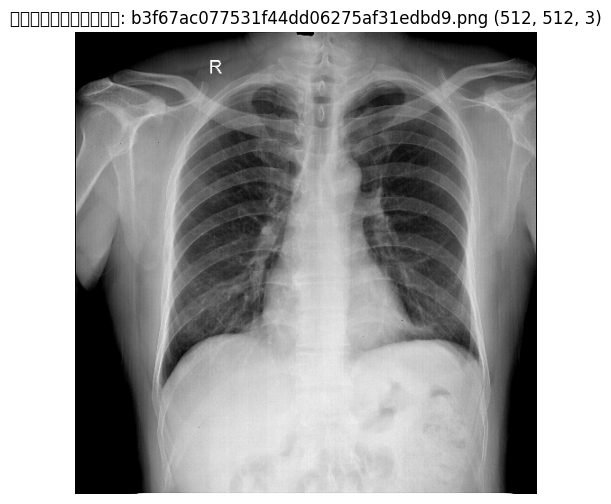

In [10]:
# 3. โหลดไฟล์ train.csv (หากมีอยู่ใน dataset)
csv_files = glob.glob(os.path.join(dataset_path, "**/*.csv"), recursive=True)
print("พบไฟล์ CSV:", csv_files)

if csv_files:
    df = pd.read_csv(csv_files[0])
    display(df.head())

# 4. ทดลองอ่านและพล็อตภาพตัวอย่าง 1 ภาพ
sample_img_path = image_files[0]
img = cv2.imread(sample_img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title(f"ตัวอย่างภาพ: {os.path.basename(sample_img_path)} {img.shape}")
plt.axis("off")
plt.show()

In [11]:
# คัดลอกภาพตัวอย่าง 10 ภาพแรกมาไว้ที่โฟลเดอร์ /content/samples
!mkdir -p /content/samples
!cp $(ls /root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1/train/*.png | head -n 10) /content/samples/

ls: cannot access '/root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1/train/*.png': No such file or directory
cp: missing destination file operand after '/content/samples/'
Try 'cp --help' for more information.


กำลังประมวลผลบน: cuda
ใช้ไฟล์ CSV จาก: /kaggle/input/vinbigdata-512-image-dataset/vinbigdata/train.csv
โฟลเดอร์รูปภาพ Train: /kaggle/input/vinbigdata-512-image-dataset/vinbigdata/train
จำนวนรูปที่พบทั้งหมด -> Normal: 10606 ภาพ | Infiltration: 613 ภาพ

สรุปการแบ่งชุดข้อมูล:
- ข้อมูลฝึก (Train): 400 ภาพ (Normal: 200, Infiltration: 200)
- ตรวจสอบ (Val)    : 80 ภาพ (Normal: 40, Infiltration: 40)
- ทดสอบ (Test)     : 100 ภาพ (Normal: 50, Infiltration: 50)

--- เริ่มต้นฝึกสอน Baseline ResNet-50 (Train 400 ภาพ, 7 Epochs) ---
Epoch [1/7] Train Loss: 0.6694 | Train Acc: 0.6025 | Val Loss: 0.6700 | Val Acc: 0.6125
Epoch [2/7] Train Loss: 0.4934 | Train Acc: 0.8950 | Val Loss: 0.5783 | Val Acc: 0.7625
Epoch [3/7] Train Loss: 0.2771 | Train Acc: 0.9425 | Val Loss: 0.4406 | Val Acc: 0.8000
Epoch [4/7] Train Loss: 0.1434 | Train Acc: 0.9675 | Val Loss: 0.3932 | Val Acc: 0.8250
Epoch [5/7] Train Loss: 0.0858 | Train Acc: 0.9775 | Val Loss: 0.3921 | Val Acc: 0.8250
Epoch [6/7] Train Loss: 0.0396 | Tra

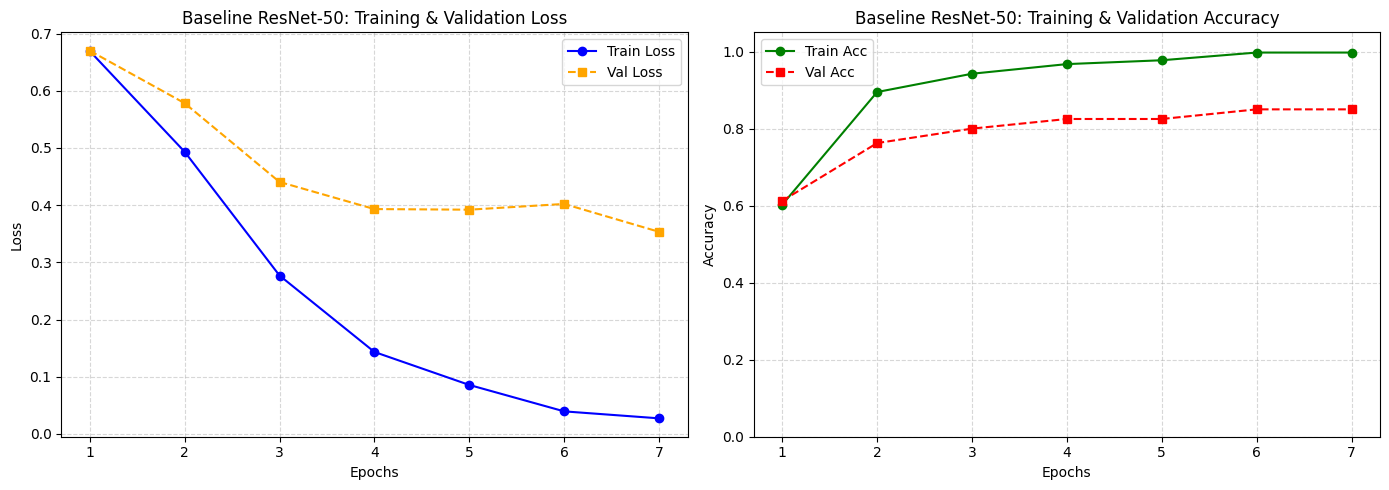

บันทึกภาพกราฟไว้ที่ 'baseline_learning_curves.png'


In [12]:
import os
import glob
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# 1. ตรวจสอบการใช้งาน GPU บน Colab
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"กำลังประมวลผลบน: {device}")

# 2. ตั้งค่า Path สำหรับชุดข้อมูล
base_path = path if ('path' in globals() and os.path.exists(path)) else '/root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1'
train_dir = os.path.join(base_path, 'vinbigdata', 'train')

if not os.path.exists(train_dir):
    train_dir = os.path.join(base_path, 'train')

csv_files = glob.glob(os.path.join(base_path, '**/*train.csv'), recursive=True)
if csv_files:
    csv_path = csv_files[0]
else:
    csv_path = glob.glob(os.path.join(base_path, '**/*.csv'), recursive=True)[0]

print(f"ใช้ไฟล์ CSV จาก: {csv_path}")
print(f"โฟลเดอร์รูปภาพ Train: {train_dir}")

# โหลด Metadata / Labels
df = pd.read_csv(csv_path)

# เตรียม Label สำหรับโจทย์ Binary Classification (Infiltration vs Normal)
if 'class_name' in df.columns:
    df_binary = df[df['class_name'].isin(['Infiltration', 'No finding'])].copy()
    df_binary['target'] = (df_binary['class_name'] == 'Infiltration').astype(int)
else:
    df_binary = df.copy()
    df_binary['target'] = (df_binary['class_id'] != 14).astype(int)

# ลดความซ้ำซ้อนของ image_id และตรวจการมีอยู่ของไฟล์รูปภาพ
df_unique = df_binary.drop_duplicates(subset=['image_id']).copy()
df_unique['img_path'] = df_unique['image_id'].apply(lambda x: os.path.join(train_dir, f"{x}.png"))
df_unique = df_unique[df_unique['img_path'].apply(os.path.exists)].reset_index(drop=True)

# -------------------------------------------------------------
# 3. ปรับให้ชุด Train มีคลาสละ 200 รูปพอดี (Balanced 200:200 ให้เท่ากับ class200_methods_colab.ipynb)
# -------------------------------------------------------------
df_class_0 = df_unique[df_unique['target'] == 0]
df_class_1 = df_unique[df_unique['target'] == 1]

print(f"จำนวนรูปที่พบทั้งหมด -> Normal: {len(df_class_0)} ภาพ | Infiltration: {len(df_class_1)} ภาพ")

# สุ่มคลาสละ 200 รูปสำหรับชุด Train (รวม 400 ภาพ)
train_df_0 = df_class_0.sample(n=200, random_state=42)
train_df_1 = df_class_1.sample(n=200, random_state=42)
train_df = pd.concat([train_df_0, train_df_1]).sample(frac=1, random_state=42).reset_index(drop=True)

# จัดสรรข้อมูลที่เหลือสำหรับ Val และ Test
remaining_0 = df_class_0.drop(train_df_0.index)
remaining_1 = df_class_1.drop(train_df_1.index)

test_df_0 = remaining_0.sample(n=50, random_state=42)
test_df_1 = remaining_1.sample(n=50, random_state=42)
test_df = pd.concat([test_df_0, test_df_1]).sample(frac=1, random_state=42).reset_index(drop=True)

remaining_0 = remaining_0.drop(test_df_0.index)
remaining_1 = remaining_1.drop(test_df_1.index)
# สุ่มคลาสละ 40 รูปสำหรับชุด Val (รวม 80 ภาพ ให้เท่ากับ class200_methods_colab.ipynb)
val_df_0 = remaining_0.sample(n=40, random_state=42)
val_df_1 = remaining_1.sample(n=40, random_state=42)
val_df = pd.concat([val_df_0, val_df_1]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nสรุปการแบ่งชุดข้อมูล:")
print(f"- ข้อมูลฝึก (Train): {len(train_df)} ภาพ (Normal: {(train_df['target']==0).sum()}, Infiltration: {(train_df['target']==1).sum()})")
print(f"- ตรวจสอบ (Val)    : {len(val_df)} ภาพ (Normal: {(val_df['target']==0).sum()}, Infiltration: {(val_df['target']==1).sum()})")
print(f"- ทดสอบ (Test)     : {len(test_df)} ภาพ (Normal: {(test_df['target']==0).sum()}, Infiltration: {(test_df['target']==1).sum()})")

# 4. กำหนด Custom Dataset และ Image Transformation
class CXRDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'img_path']
        image = Image.open(img_path).convert('RGB')
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 5. สร้าง DataLoader ตามไฮเปอร์พารามิเตอร์คงที่ (Batch Size = 32)
train_loader = DataLoader(CXRDataset(train_df, train_transform), batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(CXRDataset(val_df, val_test_transform), batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(CXRDataset(test_df, val_test_transform), batch_size=32, shuffle=False, num_workers=2)

# 6. สร้างโมเดล ResNet-50 Fixed Backbone
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# -------------------------------------------------------------
# 7. Training Loop พร้อมคำนวณ Validation และบันทึกประวัติกราฟ
# -------------------------------------------------------------
num_epochs = 7
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

print(f"\n--- เริ่มต้นฝึกสอน Baseline ResNet-50 (Train {len(train_df)} ภาพ, {num_epochs} Epochs) ---")

for epoch in range(num_epochs):
    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation Phase
    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data).item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # บันทึกค่าลง history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# บันทึก Checkpoint
torch.save(model.state_dict(), 'baseline_resnet50.pth')
print("บันทึกโมเดล baseline_resnet50.pth สำเร็จ")

# -------------------------------------------------------------
# 8. พล็อตกราฟ Loss และ Accuracy
# -------------------------------------------------------------
epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(14, 5))

# กราฟ Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], 'o-', label='Train Loss', color='blue')
plt.plot(epochs_range, history['val_loss'], 's--', label='Val Loss', color='orange')
plt.title('Baseline ResNet-50: Training & Validation Loss', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# กราฟ Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], 'o-', label='Train Acc', color='green')
plt.plot(epochs_range, history['val_acc'], 's--', label='Val Acc', color='red')
plt.title('Baseline ResNet-50: Training & Validation Accuracy', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.ylim(0.0, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.savefig('baseline_learning_curves.png', dpi=300)
plt.show()
print("บันทึกภาพกราฟไว้ที่ 'baseline_learning_curves.png'")

# **BASSLINE**

กำลังทำการทดสอบและทำนายผลบนชุดข้อมูลทดสอบ...

 ผลการประเมินโมเดล Baseline ResNet-50 (Raw CXR)
Accuracy  : 0.9200
Precision : 0.8889
Recall    : 0.9600
F1-Score  : 0.9231
ROC-AUC   : 0.9676


<Figure size 600x500 with 0 Axes>

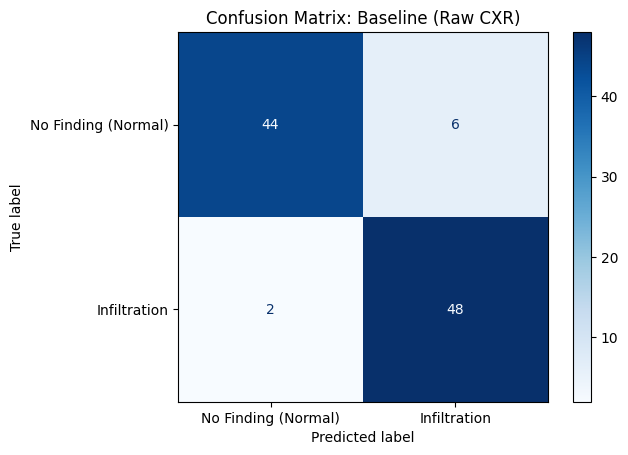

In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

# 1. โหลดน้ำหนักโมเดล Baseline ที่บันทึกไว้
model.load_state_dict(torch.load('baseline_resnet50.pth'))
model.eval()

all_preds = []
all_targets = []
all_probs = []

# 2. รันการทำนายบน test_loader
print("กำลังทำการทดสอบและทำนายผลบนชุดข้อมูลทดสอบ...")
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        # คำนวณความน่าจะเป็นของคลาสบวก (Infiltration)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        _, preds = torch.max(outputs, 1)

        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

all_targets = np.array(all_targets)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)

# 3. คำนวณตัวชี้วัดทางการแพทย์
acc = accuracy_score(all_targets, all_preds)
prec = precision_score(all_targets, all_preds, zero_division=0)
rec = recall_score(all_targets, all_preds, zero_division=0)
f1 = f1_score(all_targets, all_preds, zero_division=0)
roc_auc = roc_auc_score(all_targets, all_probs)

print("\n" + "="*50)
print(" ผลการประเมินโมเดล Baseline ResNet-50 (Raw CXR)")
print("="*50)
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print("="*50)

# 4. พล็อต Confusion Matrix ตามรูปแบบตารางการทดลอง
cm = confusion_matrix(all_targets, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Finding (Normal)', 'Infiltration'])

plt.figure(figsize=(6, 5))
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix: Baseline (Raw CXR)")
plt.grid(False)
plt.show()

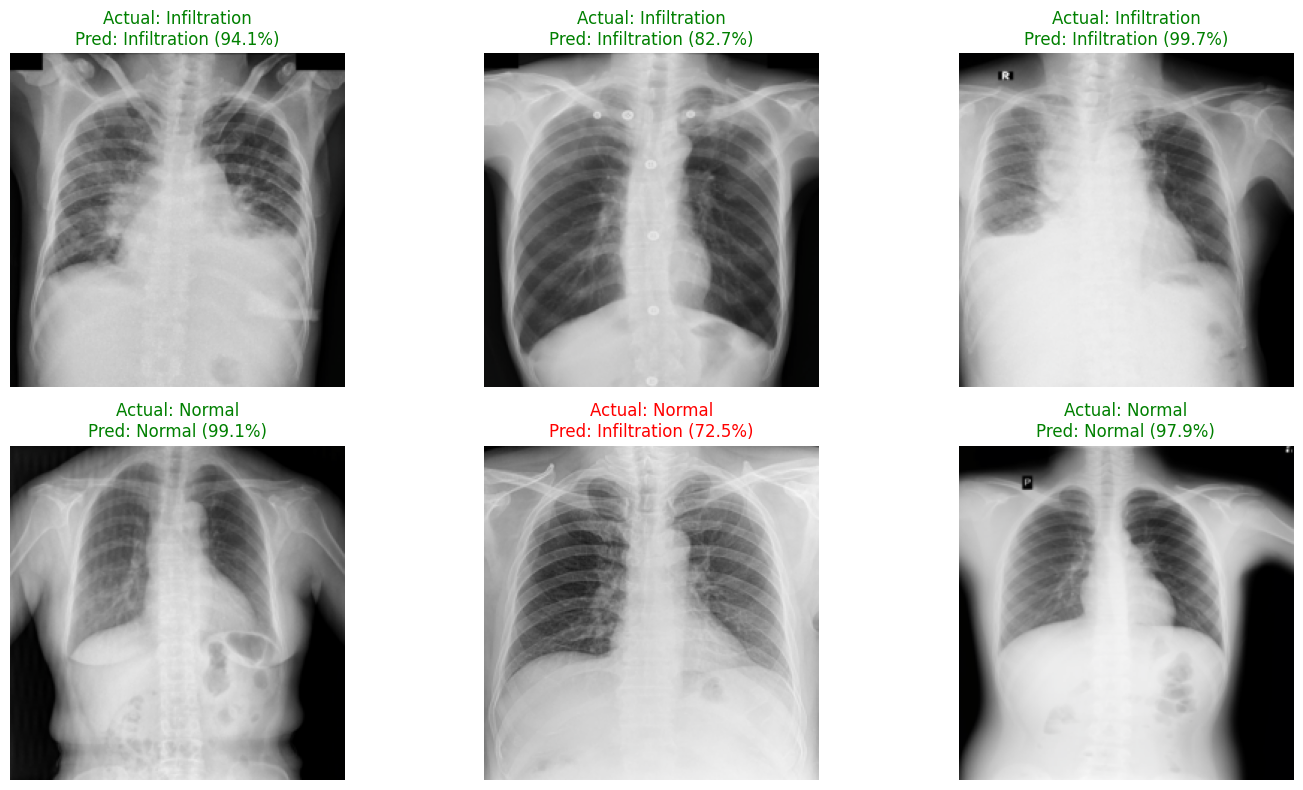

In [14]:
# ดึง 6 ภาพแรกจาก test_loader มาแสดงผลพร้อมผลทำนาย
data_iter = iter(test_loader)
images, labels = next(data_iter)

with torch.no_grad():
    outputs = model(images.to(device))
    probs = torch.softmax(outputs, dim=1)
    _, preds = torch.max(outputs, 1)

class_names = ['Normal', 'Infiltration']

plt.figure(figsize=(15, 8))
for i in range(min(6, len(images))):
    plt.subplot(2, 3, i + 1)
    # แปลง Tensor กลับเป็นภาพปกติ
    img_display = images[i].permute(1, 2, 0).cpu().numpy()
    img_display = img_display * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
    img_display = np.clip(img_display, 0, 1)

    actual_label = class_names[labels[i].item()]
    predicted_label = class_names[preds[i].item()]
    confidence = probs[i][preds[i].item()].item() * 100

    color = 'green' if actual_label == predicted_label else 'red'

    plt.imshow(img_display)
    plt.title(f"Actual: {actual_label}\nPred: {predicted_label} ({confidence:.1f}%)", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

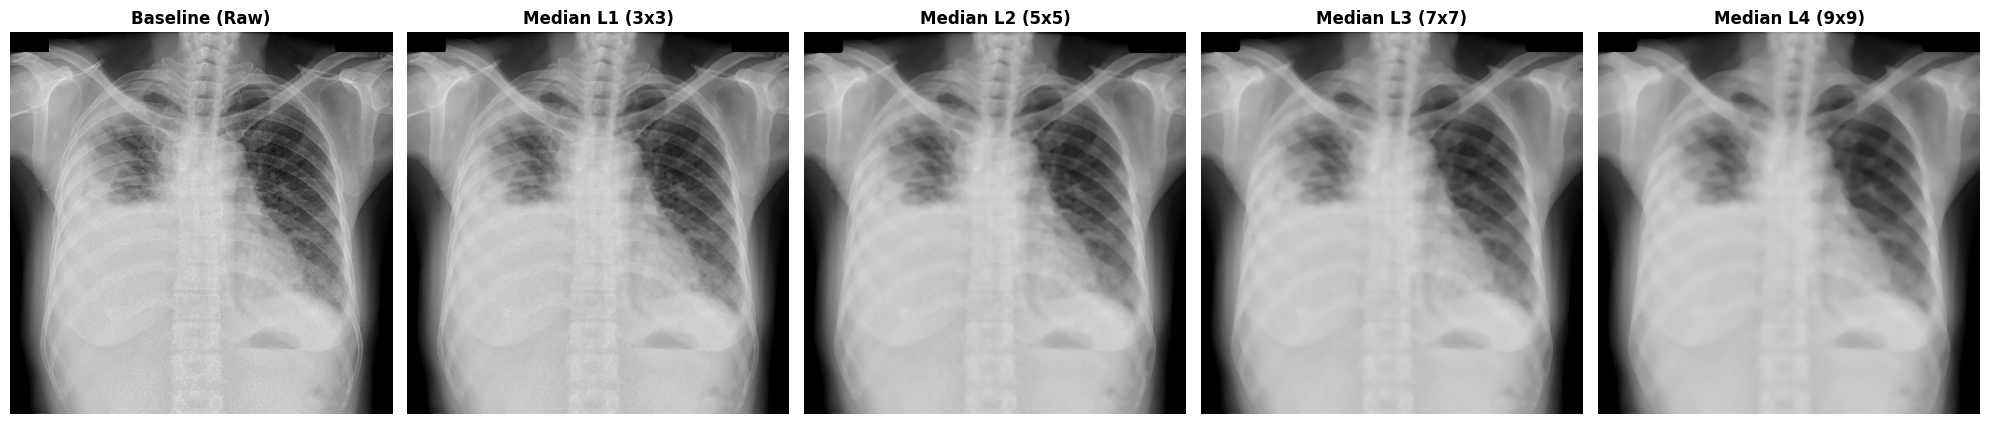

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. ฟังก์ชันประมวลผล Median Filter แต่ละระดับ
def apply_median_filter(image_pil, level='L1'):
    # แปลงเป็น Grayscale NumPy array
    img_gray = np.array(image_pil.convert('L'))

    if level == 'Baseline':
        processed = img_gray
    elif level == 'L1':
        processed = cv2.medianBlur(img_gray, 3)  # Kernel 3x3
    elif level == 'L2':
        processed = cv2.medianBlur(img_gray, 5)  # Kernel 5x5
    elif level == 'L3':
        processed = cv2.medianBlur(img_gray, 7)  # Kernel 7x7
    elif level == 'L4':
        processed = cv2.medianBlur(img_gray, 9)  # Kernel 9x9 (เพิ่มเติม)
    else:
        processed = img_gray

    return Image.fromarray(processed).convert('RGB')

# 2. ดึงภาพตัวอย่างจากชุด Train มาทดสอบแสดงผล
sample_img_path = train_df.iloc[0]['img_path']
raw_sample = Image.open(sample_img_path)

# ประมวลผลภาพในแต่ละระดับ
img_base = apply_median_filter(raw_sample, 'Baseline')
img_l1 = apply_median_filter(raw_sample, 'L1')
img_l2 = apply_median_filter(raw_sample, 'L2')
img_l3 = apply_median_filter(raw_sample, 'L3')
img_l4 = apply_median_filter(raw_sample, 'L4')

# 3. พล็อตเปรียบเทียบความแตกต่าง
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
titles = [
    'Baseline (Raw)',
    'Median L1 (3x3)',
    'Median L2 (5x5)',
    'Median L3 (7x7)',
    'Median L4 (9x9)'
]
images = [img_base, img_l1, img_l2, img_l3, img_l4]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [16]:
class DenoisedCXRDataset(Dataset):
    def __init__(self, dataframe, filter_level='L1', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.filter_level = filter_level
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'img_path']
        image = Image.open(img_path).convert('RGB')

        # นำภาพไปผ่าน Median Filter ตามระดับที่กำหนดก่อน
        image = apply_median_filter(image, level=self.filter_level)
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# ตัวอย่างการสร้าง DataLoader สำหรับ Median Filter L1
train_loader_median_l1 = DataLoader(
    DenoisedCXRDataset(train_df, filter_level='L1', transform=train_transform),
    batch_size=32, shuffle=True, num_workers=2
)
val_loader_median_l1 = DataLoader(
    DenoisedCXRDataset(val_df, filter_level='L1', transform=val_test_transform),
    batch_size=32, shuffle=False, num_workers=2
)

# **Median Filter L1 - L4**

 เริ่มการทดลองฝึกสอน Median Filter Pipeline (L1 - L4)

>>> [กำลังเริ่มการทดลอง: Median Filter L1] <<<
Epoch [01/07] Loss: 0.6576 | Train Acc: 0.6525
Epoch [04/07] Loss: 0.1349 | Train Acc: 0.9700
Epoch [07/07] Loss: 0.0251 | Train Acc: 0.9975

>>> [กำลังเริ่มการทดลอง: Median Filter L2] <<<
Epoch [01/07] Loss: 0.6751 | Train Acc: 0.6300
Epoch [04/07] Loss: 0.1385 | Train Acc: 0.9675
Epoch [07/07] Loss: 0.0329 | Train Acc: 0.9950

>>> [กำลังเริ่มการทดลอง: Median Filter L3] <<<
Epoch [01/07] Loss: 0.6639 | Train Acc: 0.6250
Epoch [04/07] Loss: 0.1793 | Train Acc: 0.9400
Epoch [07/07] Loss: 0.0459 | Train Acc: 0.9900

>>> [กำลังเริ่มการทดลอง: Median Filter L4] <<<
Epoch [01/07] Loss: 0.6587 | Train Acc: 0.6600
Epoch [04/07] Loss: 0.1531 | Train Acc: 0.9625
Epoch [07/07] Loss: 0.0464 | Train Acc: 0.9925

 สรุปผลการประเมินโมเดล Median Filter แต่ละระดับ (Classification Table)


,สภาวะการทดลอง,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Median Filter L1,0.8800,0.9750,0.7800,0.8667,0.9636
1,Median Filter L2,0.9000,0.8846,0.9200,0.9020,0.9624
2,Median Filter L3,0.9100,0.9362,0.8800,0.9072,0.9680
3,Median Filter L4,0.8700,0.8364,0.9200,0.8762,0.9528


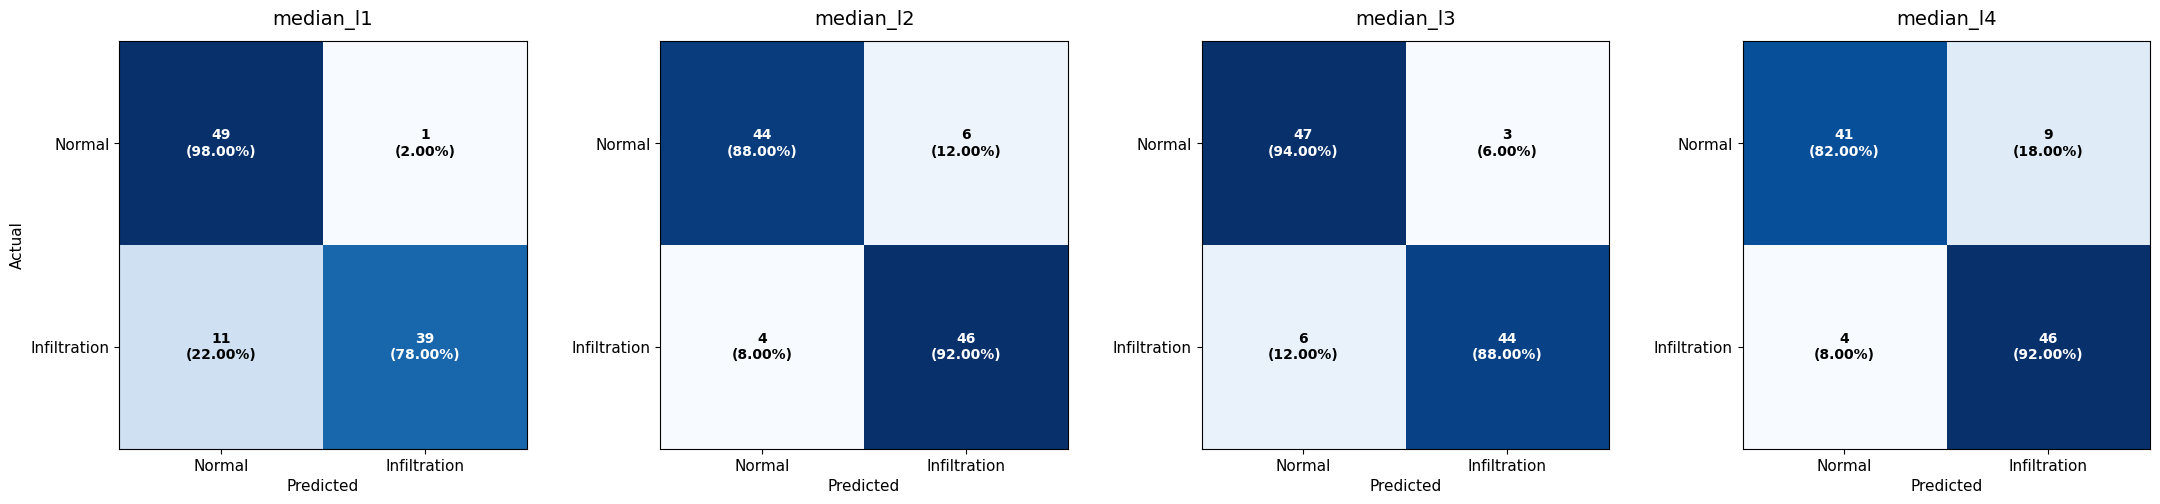

บันทึกภาพ Confusion Matrix เรียบร้อยแล้วที่ 'confusion_matrices_median_L1_L4.png'


In [17]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# 1. ฟังก์ชันตัวกรอง Median Filter ตามระดับ Kernel
def apply_median_filter(pil_img, level='L1'):
    img_gray = np.array(pil_img.convert('L'))
    kernel_sizes = {'L1': 3, 'L2': 5, 'L3': 7, 'L4': 9}
    ksize = kernel_sizes.get(level, 3)
    filtered = cv2.medianBlur(img_gray, ksize)
    return Image.fromarray(filtered).convert('RGB')

# 2. Custom Dataset รองรับการทำ Median Filter
class DenoisedCXRDataset(Dataset):
    def __init__(self, dataframe, filter_level='L1', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.filter_level = filter_level
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'img_path']
        image = Image.open(img_path).convert('RGB')
        image = apply_median_filter(image, self.filter_level)
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# 3. เตรียมการทดลองวนลูป L1 ถึง L4
filter_levels = ['L1', 'L2', 'L3', 'L4']
results = []
confusion_matrices = {}

print("==================================================")
print(" เริ่มการทดลองฝึกสอน Median Filter Pipeline (L1 - L4)")
print("==================================================")

for level in filter_levels:
    print(f"\n>>> [กำลังเริ่มการทดลอง: Median Filter {level}] <<<")

    # สร้าง DataLoaders เฉพาะของระดับนั้น
    lvl_train_loader = DataLoader(
        DenoisedCXRDataset(train_df, filter_level=level, transform=train_transform),
        batch_size=32, shuffle=True, num_workers=2
    )
    lvl_test_loader = DataLoader(
        DenoisedCXRDataset(test_df, filter_level=level, transform=val_test_transform),
        batch_size=32, shuffle=False, num_workers=2
    )

    # รีเซ็ตสถาปัตยกรรมโมเดล ResNet-50 ใหม่ทุกรอบเพื่อ Fair Comparison
    lvl_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    lvl_model.fc = nn.Linear(lvl_model.fc.in_features, 2)
    lvl_model = lvl_model.to(device)

    lvl_criterion = nn.CrossEntropyLoss()
    lvl_optimizer = torch.optim.Adam(lvl_model.parameters(), lr=1e-4)

    # ฝึกสอนโมเดล 7 Epochs
    lvl_model.train()
    for epoch in range(7):
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in lvl_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            lvl_optimizer.zero_grad()
            outputs = lvl_model(imgs)
            loss = lvl_criterion(outputs, lbls)
            loss.backward()
            lvl_optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == lbls.data).item()
            total += lbls.size(0)

        if (epoch + 1) in [1, 4, 7]:
            print(f"Epoch [{epoch+1:02d}/07] Loss: {running_loss/total:.4f} | Train Acc: {correct/total:.4f}")

    # บันทึก Checkpoint
    model_save_path = f"median_{level.lower()}_resnet50.pth"
    torch.save(lvl_model.state_dict(), model_save_path)

    # 4. ทดสอบและประเมินผลบนชุดทดสอบมาตรฐาน (Test Set 100 เคส)
    lvl_model.eval()
    all_preds, all_targets, all_probs = [], [], []
    with torch.no_grad():
        for imgs, lbls in lvl_test_loader:
            imgs = imgs.to(device)
            outputs = lvl_model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(lbls.numpy())

    all_targets = np.array(all_targets)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    # คำนวณตัวชี้วัด
    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    roc = roc_auc_score(all_targets, all_probs)

    results.append({
        'สภาวะการทดลอง': f'Median Filter {level}',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

    # เก็บ Confusion Matrix
    confusion_matrices[level] = confusion_matrix(all_targets, all_preds)

# -------------------------------------------------------------
# 5. แสดงตารางสรุปผลลัพธ์การทดลอง
# -------------------------------------------------------------
df_results = pd.DataFrame(results)
print("\n" + "="*70)
print(" สรุปผลการประเมินโมเดล Median Filter แต่ละระดับ (Classification Table)")
print("="*70)
display(df_results.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))

# -------------------------------------------------------------
# 6. พล็อต Confusion Matrices เรียงต่อกัน 4 ระดับ
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_labels = ['Normal', 'Infiltration']

for idx, level in enumerate(filter_levels):
    cm = confusion_matrices[level]
    ax = axes[idx]

    # วาดตาราง Heatmap สีฟ้าตามรูปแบบตารางรายงาน
    cax = ax.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    ax.set_title(f'median_{level.lower()}', fontsize=14, pad=12)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels, fontsize=11)
    ax.set_yticklabels(class_labels, fontsize=11)
    ax.set_xlabel('Predicted', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Actual', fontsize=11)

    # ใส่ตัวเลขจำนวนและเปอร์เซ็นต์ในแต่ละช่อง
    for i in range(2):
        row_sum = cm[i].sum()
        for j in range(2):
            count = cm[i, j]
            pct = (count / row_sum * 100) if row_sum > 0 else 0
            text_color = "white" if count > (cm.max() / 2) else "black"
            ax.text(j, i, f"{count}\n({pct:.2f}%)", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices_median_L1_L4.png', dpi=300)
plt.show()
print("บันทึกภาพ Confusion Matrix เรียบร้อยแล้วที่ 'confusion_matrices_median_L1_L4.png'")

# **CLAHE + DWT (L1 – L4)**

 เริ่มการทดลองฝึกสอน CLAHE + DWT Pipeline (L1 - L4)

>>> [กำลังเริ่มการทดลอง: CLAHE + DWT L1] <<<
Epoch [01/07] Loss: 0.6532 | Train Acc: 0.6500
Epoch [04/07] Loss: 0.1391 | Train Acc: 0.9750
Epoch [07/07] Loss: 0.0249 | Train Acc: 1.0000
บันทึกโมเดล clahe_dwt_l1_resnet50.pth เรียบร้อย

>>> [กำลังเริ่มการทดลอง: CLAHE + DWT L2] <<<
Epoch [01/07] Loss: 0.6615 | Train Acc: 0.6375
Epoch [04/07] Loss: 0.1153 | Train Acc: 0.9775
Epoch [07/07] Loss: 0.0444 | Train Acc: 0.9925
บันทึกโมเดล clahe_dwt_l2_resnet50.pth เรียบร้อย

>>> [กำลังเริ่มการทดลอง: CLAHE + DWT L3] <<<
Epoch [01/07] Loss: 0.6498 | Train Acc: 0.6975
Epoch [04/07] Loss: 0.1143 | Train Acc: 0.9700
Epoch [07/07] Loss: 0.0258 | Train Acc: 0.9950
บันทึกโมเดล clahe_dwt_l3_resnet50.pth เรียบร้อย

>>> [กำลังเริ่มการทดลอง: CLAHE + DWT L4] <<<
Epoch [01/07] Loss: 0.6642 | Train Acc: 0.6475
Epoch [04/07] Loss: 0.1127 | Train Acc: 0.9775
Epoch [07/07] Loss: 0.0384 | Train Acc: 0.9925
บันทึกโมเดล clahe_dwt_l4_resnet50.pth เรียบร้อย

 ผลการป

,สภาวะการทดลอง,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,CLAHE + DWT L1,0.8700,0.8627,0.8800,0.8713,0.9512
1,CLAHE + DWT L2,0.9100,0.9767,0.8400,0.9032,0.9628
2,CLAHE + DWT L3,0.8900,0.8305,0.9800,0.8991,0.9620
3,CLAHE + DWT L4,0.8500,0.7966,0.9400,0.8624,0.9500


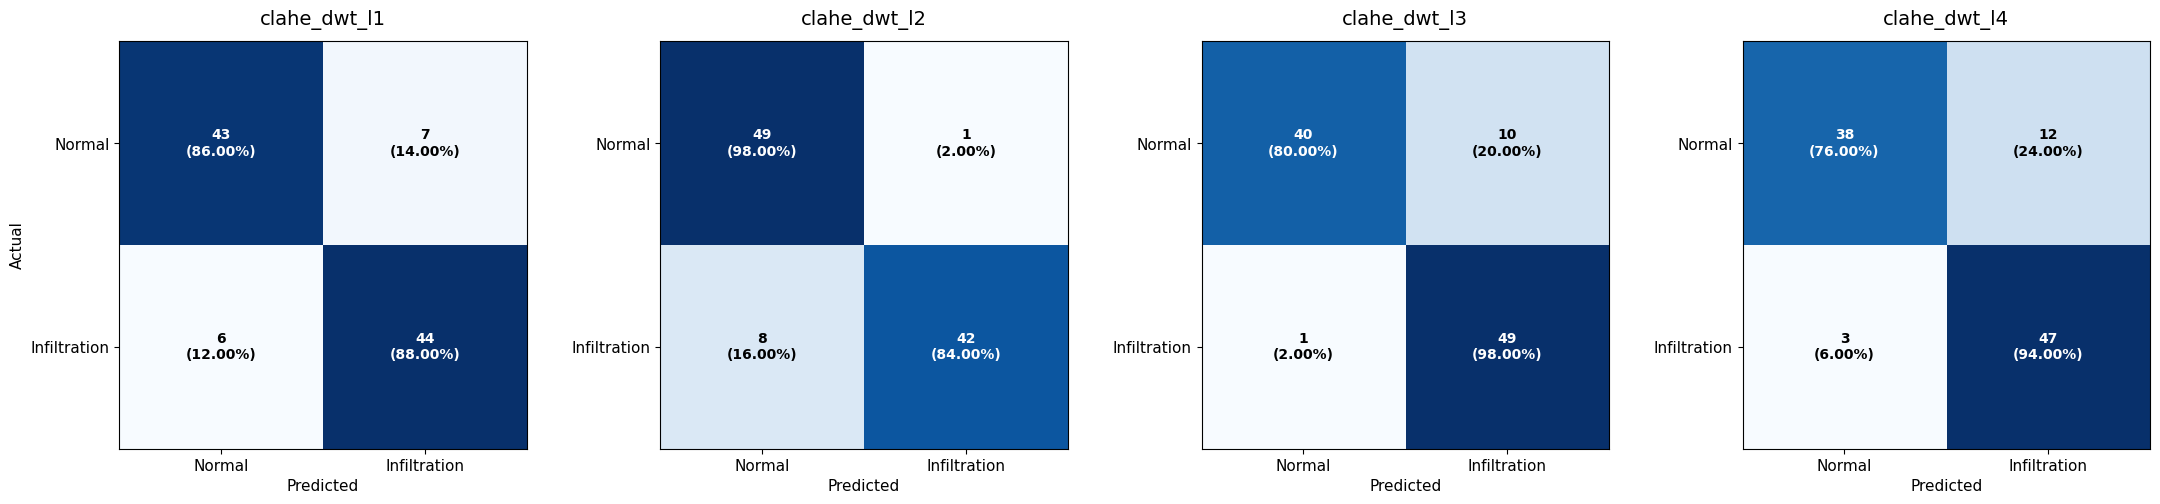

บันทึกภาพ Confusion Matrix ที่ 'confusion_matrices_clahe_dwt_L1_L4.png'


In [18]:
import os
import cv2
import pywt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# 1. ฟังก์ชัน CLAHE + DWT ตามระเบียบวิธีวิจัย (Wavelet: db1)
def apply_clahe_dwt(pil_img, level='L1'):
    img_np = np.array(pil_img.convert('L'), dtype=np.uint8)

    # พารามิเตอร์ของแต่ละระดับ L1 - L4
    params = {
        'L1': {'clip_limit': 1.0, 'thresh_ratio': 0.05},
        'L2': {'clip_limit': 2.0, 'thresh_ratio': 0.10},
        'L3': {'clip_limit': 3.0, 'thresh_ratio': 0.20},
        'L4': {'clip_limit': 4.0, 'thresh_ratio': 0.30}
    }
    cfg = params.get(level, params['L1'])

    # ขั้นตอนที่ 1: Contrast Limited Adaptive Histogram Equalization (CLAHE)
    clahe = cv2.createCLAHE(clipLimit=cfg['clip_limit'], tileGridSize=(8, 8))
    enhanced_img = clahe.apply(img_np)

    # ขั้นตอนที่ 2: Discrete Wavelet Transform (2D DWT - Wavelet 'db1')
    coeffs2 = pywt.dwt2(enhanced_img.astype(np.float32), 'db1')
    LL, (LH, HL, HH) = coeffs2

    # กรองสัมประสิทธิ์ความถี่สูงด้วย Soft Thresholding
    threshold = cfg['thresh_ratio'] * np.max([np.abs(LH), np.abs(HL), np.abs(HH)])
    LH_thresh = pywt.threshold(LH, threshold, mode='soft')
    HL_thresh = pywt.threshold(HL, threshold, mode='soft')
    HH_thresh = pywt.threshold(HH, threshold, mode='soft')

    # ขั้นตอนที่ 3: สังเคราะห์ภาพกลับ (Inverse 2D DWT)
    reconstructed = pywt.idwt2((LL, (LH_thresh, HL_thresh, HH_thresh)), 'db1')
    reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)

    return Image.fromarray(reconstructed).convert('RGB')

# 2. Custom Dataset สำหรับ CLAHE + DWT
class ClaheDwtCXRDataset(Dataset):
    def __init__(self, dataframe, filter_level='L1', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.filter_level = filter_level
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'img_path']
        image = Image.open(img_path).convert('RGB')

        # ส่งผ่านอัลกอริทึม CLAHE + DWT
        image = apply_clahe_dwt(image, self.filter_level)
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# 3. เริ่มกระบวนการทดลองวนลูป L1 ถึง L4
filter_levels = ['L1', 'L2', 'L3', 'L4']
results = []
confusion_matrices = {}

print("======================================================")
print(" เริ่มการทดลองฝึกสอน CLAHE + DWT Pipeline (L1 - L4)")
print("======================================================")

for level in filter_levels:
    print(f"\n>>> [กำลังเริ่มการทดลอง: CLAHE + DWT {level}] <<<")

    # DataLoader ประจำระดับ
    lvl_train_loader = DataLoader(
        ClaheDwtCXRDataset(train_df, filter_level=level, transform=train_transform),
        batch_size=32, shuffle=True, num_workers=2
    )
    lvl_test_loader = DataLoader(
        ClaheDwtCXRDataset(test_df, filter_level=level, transform=val_test_transform),
        batch_size=32, shuffle=False, num_workers=2
    )

    # รีเซ็ตโครงข่าย ResNet-50 ใหม่ทุกรอบเพื่อความยุติธรรม (Fair Comparison)
    lvl_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    lvl_model.fc = nn.Linear(lvl_model.fc.in_features, 2)
    lvl_model = lvl_model.to(device)

    lvl_criterion = nn.CrossEntropyLoss()
    lvl_optimizer = torch.optim.Adam(lvl_model.parameters(), lr=1e-4)

    # ฝึกสอน 7 Epochs
    lvl_model.train()
    for epoch in range(7):
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in lvl_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            lvl_optimizer.zero_grad()
            outputs = lvl_model(imgs)
            loss = lvl_criterion(outputs, lbls)
            loss.backward()
            lvl_optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == lbls.data).item()
            total += lbls.size(0)

        if (epoch + 1) in [1, 4, 7]:
            print(f"Epoch [{epoch+1:02d}/07] Loss: {running_loss/total:.4f} | Train Acc: {correct/total:.4f}")

    # บันทึก Checkpoint โมเดล
    save_name = f"clahe_dwt_{level.lower()}_resnet50.pth"
    torch.save(lvl_model.state_dict(), save_name)
    print(f"บันทึกโมเดล {save_name} เรียบร้อย")

    # 4. ทดสอบและประเมินผลบนชุดทดสอบมาตรฐาน (Test Set 100 เคส)
    lvl_model.eval()
    all_preds, all_targets, all_probs = [], [], []
    with torch.no_grad():
        for imgs, lbls in lvl_test_loader:
            imgs = imgs.to(device)
            outputs = lvl_model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(lbls.numpy())

    all_targets = np.array(all_targets)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    # คำนวณ Metric ทางการแพทย์
    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    roc = roc_auc_score(all_targets, all_probs)

    results.append({
        'สภาวะการทดลอง': f'CLAHE + DWT {level}',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

    confusion_matrices[level] = confusion_matrix(all_targets, all_preds)

# -------------------------------------------------------------
# 5. แสดงตารางสรุปผลลัพธ์
# -------------------------------------------------------------
df_results = pd.DataFrame(results)
print("\n" + "="*70)
print(" ผลการประเมินการจำแนกโรคกลุ่ม CLAHE + DWT (L1 - L4)")
print("="*70)
display(df_results.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))

# -------------------------------------------------------------
# 6. พล็อต Confusion Matrices 4 ระดับเปรียบเทียบกัน
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_labels = ['Normal', 'Infiltration']

for idx, level in enumerate(filter_levels):
    cm = confusion_matrices[level]
    ax = axes[idx]

    cax = ax.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    ax.set_title(f'clahe_dwt_{level.lower()}', fontsize=14, pad=12)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels, fontsize=11)
    ax.set_yticklabels(class_labels, fontsize=11)
    ax.set_xlabel('Predicted', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Actual', fontsize=11)

    for i in range(2):
        row_sum = cm[i].sum()
        for j in range(2):
            count = cm[i, j]
            pct = (count / row_sum * 100) if row_sum > 0 else 0
            text_color = "white" if count > (cm.max() / 2) else "black"
            ax.text(j, i, f"{count}\n({pct:.2f}%)", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices_clahe_dwt_L1_L4.png', dpi=300)
plt.show()
print("บันทึกภาพ Confusion Matrix ที่ 'confusion_matrices_clahe_dwt_L1_L4.png'")

# **DAE + CLAHE L1 - L4**

--- กำลังฝึกสอนโมเดล DAE เบื้องต้น ---
DAE Pretrain Epoch [1/5] Loss: 0.01826
DAE Pretrain Epoch [2/5] Loss: 0.00372
DAE Pretrain Epoch [3/5] Loss: 0.00250
DAE Pretrain Epoch [4/5] Loss: 0.00230
DAE Pretrain Epoch [5/5] Loss: 0.00197
กำลัง Pre-process ภาพชุด train (400 ภาพ)...
กำลัง Pre-process ภาพชุด test (100 ภาพ)...
แคชภาพ DAE + CLAHE ทั้งหมดเรียบร้อยแล้ว!

 เริ่มการทดลองฝึกสอน DAE + CLAHE Pipeline (L1 - L4)

>>> [กำลังเริ่มการทดลอง: DAE + CLAHE L1] <<<
Epoch [01/07] Loss: 0.6776 | Train Acc: 0.5825
Epoch [04/07] Loss: 0.2234 | Train Acc: 0.9600
Epoch [07/07] Loss: 0.0740 | Train Acc: 0.9775

>>> [กำลังเริ่มการทดลอง: DAE + CLAHE L2] <<<
Epoch [01/07] Loss: 0.6922 | Train Acc: 0.5250
Epoch [04/07] Loss: 0.2328 | Train Acc: 0.9425
Epoch [07/07] Loss: 0.0632 | Train Acc: 0.9800

>>> [กำลังเริ่มการทดลอง: DAE + CLAHE L3] <<<
Epoch [01/07] Loss: 0.6792 | Train Acc: 0.5775
Epoch [04/07] Loss: 0.2370 | Train Acc: 0.9475
Epoch [07/07] Loss: 0.0469 | Train Acc: 0.9950

>>> [กำลังเริ่มการทดลอง

,สภาวะการทดลอง,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,DAE + CLAHE L1,0.8800,0.8800,0.8800,0.8800,0.9604
1,DAE + CLAHE L2,0.8800,0.9130,0.8400,0.8750,0.9476
2,DAE + CLAHE L3,0.8900,0.8679,0.9200,0.8932,0.9440
3,DAE + CLAHE L4,0.9000,0.9348,0.8600,0.8958,0.9588


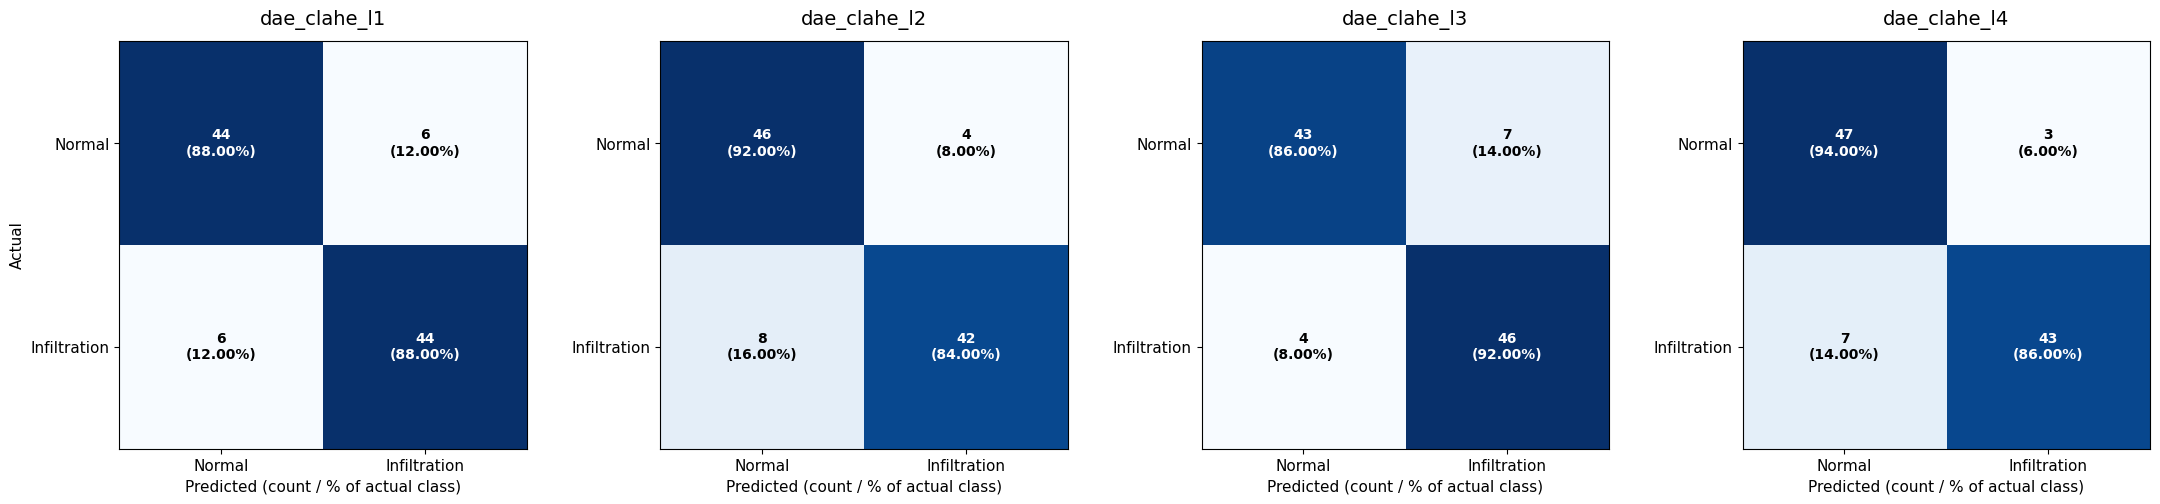

บันทึกภาพ Confusion Matrix สำเร็จที่ 'confusion_matrices_dae_clahe_L1_L4.png'


In [19]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# -------------------------------------------------------------
# 1. โครงสร้าง Denoising Autoencoder (DAE)
# -------------------------------------------------------------
class ConvDAE(nn.Module):
    def __init__(self):
        super(ConvDAE, self).__init__()
        self.enc1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        self.enc2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        self.dec1 = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.dec2 = nn.Sequential(
            nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2),
            nn.Sigmoid()
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        d1 = self.dec1(e2)
        out = self.dec2(d1)
        return out

# ฝึกสอน DAE แบบย่อด้วย Gaussian Noise (Unsupervised)
print("--- กำลังฝึกสอนโมเดล DAE เบื้องต้น ---")
dae_model = ConvDAE().to(device)
dae_optimizer = torch.optim.Adam(dae_model.parameters(), lr=1e-3)
dae_criterion = nn.MSELoss()

class DAETrainingDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)
        self.resize = transforms.Resize((224, 224))
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img = Image.open(self.df.loc[idx, 'img_path']).convert('L')
        clean_tensor = self.to_tensor(self.resize(img))
        noise = torch.randn_like(clean_tensor) * 0.08
        noisy_tensor = torch.clamp(clean_tensor + noise, 0., 1.)
        return noisy_tensor, clean_tensor

# ใช้ num_workers=0 สำหรับการเทรน DAE เพื่อป้องกัน CUDA subprocess issue
dae_loader = DataLoader(DAETrainingDataset(train_df), batch_size=16, shuffle=True, num_workers=0)

dae_model.train()
for d_epoch in range(5):
    d_loss = 0.0
    for noisy_imgs, clean_imgs in dae_loader:
        noisy_imgs, clean_imgs = noisy_imgs.to(device), clean_imgs.to(device)
        dae_optimizer.zero_grad()
        recon = dae_model(noisy_imgs)
        loss = dae_criterion(recon, clean_imgs)
        loss.backward()
        dae_optimizer.step()
        d_loss += loss.item() * noisy_imgs.size(0)
    print(f"DAE Pretrain Epoch [{d_epoch+1}/5] Loss: {d_loss/len(train_df):.5f}")

dae_model.eval()

# -------------------------------------------------------------
# 2. ฟังก์ชันประมวลผล DAE + CLAHE (Pre-process ล่วงหน้า)
# -------------------------------------------------------------
clip_limits = {'L1': 2.0, 'L2': 4.0, 'L3': 8.0, 'L4': 10.0}

def preprocess_and_save_dataset(df_subset, subset_name):
    """รัน DAE บน GPU ล่วงหน้าครั้งเดียวและสร้างภาพ CLAHE แต่ละระดับลงโฟลเดอร์"""
    to_tensor = transforms.ToTensor()
    resize = transforms.Resize((224, 224))

    # สร้างโฟลเดอร์เก็บภาพที่ประมวลผลแล้ว
    for lvl in ['L1', 'L2', 'L3', 'L4']:
        os.makedirs(f"/content/dae_cache/{subset_name}/{lvl}", exist_ok=True)

    print(f"กำลัง Pre-process ภาพชุด {subset_name} ({len(df_subset)} ภาพ)...")
    with torch.no_grad():
        for _, row in df_subset.iterrows():
            img_id = row['image_id']
            img = Image.open(row['img_path']).convert('L')
            img_t = to_tensor(resize(img)).unsqueeze(0).to(device)

            # กรอง Noise ด้วย DAE
            denoised_t = dae_model(img_t).squeeze().cpu().numpy()
            denoised_np = np.clip(denoised_t * 255.0, 0, 255).astype(np.uint8)

            # ประยุกต์ใช้ CLAHE ตามระดับ Clip Limit
            for lvl, clip_val in clip_limits.items():
                clahe = cv2.createCLAHE(clipLimit=clip_val, tileGridSize=(8, 8))
                enhanced_np = clahe.apply(denoised_np)
                save_path = f"/content/dae_cache/{subset_name}/{lvl}/{img_id}.png"
                cv2.imwrite(save_path, enhanced_np)

# ทำแคชล่วงหน้าสำหรับทั้ง Train และ Test
preprocess_and_save_dataset(train_df, "train")
preprocess_and_save_dataset(test_df, "test")
print("แคชภาพ DAE + CLAHE ทั้งหมดเรียบร้อยแล้ว!")

# -------------------------------------------------------------
# 3. Custom Dataset โหลดภาพจากแคชโดยตรง (ทำงานร่วมกับ num_workers=2 ได้ 100%)
# -------------------------------------------------------------
class CachedDaeClaheDataset(Dataset):
    def __init__(self, dataframe, subset_name="train", level='L1', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.subset_name = subset_name
        self.level = level
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_id = self.df.loc[idx, 'image_id']
        cached_path = f"/content/dae_cache/{self.subset_name}/{self.level}/{img_id}.png"
        image = Image.open(cached_path).convert('RGB')
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# -------------------------------------------------------------
# 4. ฝึกสอน ResNet-50 เปรียบเทียบ DAE + CLAHE (L1 - L4)
# -------------------------------------------------------------
filter_levels = ['L1', 'L2', 'L3', 'L4']
results = []
confusion_matrices = {}

print("\n========================================================")
print(" เริ่มการทดลองฝึกสอน DAE + CLAHE Pipeline (L1 - L4)")
print("========================================================")

for level in filter_levels:
    print(f"\n>>> [กำลังเริ่มการทดลอง: DAE + CLAHE {level}] <<<")

    lvl_train_loader = DataLoader(
        CachedDaeClaheDataset(train_df, "train", level=level, transform=train_transform),
        batch_size=32, shuffle=True, num_workers=2
    )
    lvl_test_loader = DataLoader(
        CachedDaeClaheDataset(test_df, "test", level=level, transform=val_test_transform),
        batch_size=32, shuffle=False, num_workers=2
    )

    lvl_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    lvl_model.fc = nn.Linear(lvl_model.fc.in_features, 2)
    lvl_model = lvl_model.to(device)

    lvl_criterion = nn.CrossEntropyLoss()
    lvl_optimizer = torch.optim.Adam(lvl_model.parameters(), lr=1e-4)

    # เทรน 7 Epochs
    lvl_model.train()
    for epoch in range(7):
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in lvl_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            lvl_optimizer.zero_grad()
            outputs = lvl_model(imgs)
            loss = lvl_criterion(outputs, lbls)
            loss.backward()
            lvl_optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == lbls.data).item()
            total += lbls.size(0)

        if (epoch + 1) in [1, 4, 7]:
            print(f"Epoch [{epoch+1:02d}/07] Loss: {running_loss/total:.4f} | Train Acc: {correct/total:.4f}")

    # บันทึก Checkpoint
    save_name = f"dae_clahe_{level.lower()}_resnet50.pth"
    torch.save(lvl_model.state_dict(), save_name)

    # ประเมินผลบนชุดทดสอบมาตรฐาน (Test Set 100 เคส)
    lvl_model.eval()
    all_preds, all_targets, all_probs = [], [], []
    with torch.no_grad():
        for imgs, lbls in lvl_test_loader:
            imgs = imgs.to(device)
            outputs = lvl_model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(lbls.numpy())

    all_targets = np.array(all_targets)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    roc = roc_auc_score(all_targets, all_probs)

    results.append({
        'สภาวะการทดลอง': f'DAE + CLAHE {level}',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

    confusion_matrices[level] = confusion_matrix(all_targets, all_preds)

# -------------------------------------------------------------
# 5. แสดงผลตารางสรุป Metric ทางการแพทย์
# -------------------------------------------------------------
df_results = pd.DataFrame(results)
print("\n" + "="*70)
print(" สรุปผลการประเมินการจำแนกโรคกลุ่ม DAE + CLAHE (L1 - L4)")
print("="*70)
display(df_results.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))

# -------------------------------------------------------------
# 6. พล็อต Confusion Matrices 4 ช่อง
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_labels = ['Normal', 'Infiltration']

for idx, level in enumerate(filter_levels):
    cm = confusion_matrices[level]
    ax = axes[idx]

    ax.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    ax.set_title(f'dae_clahe_{level.lower()}', fontsize=14, pad=12)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels, fontsize=11)
    ax.set_yticklabels(class_labels, fontsize=11)
    ax.set_xlabel('Predicted (count / % of actual class)', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Actual', fontsize=11)

    for i in range(2):
        row_sum = cm[i].sum()
        for j in range(2):
            count = cm[i, j]
            pct = (count / row_sum * 100) if row_sum > 0 else 0
            text_color = "white" if count > (cm.max() / 2) else "black"
            ax.text(j, i, f"{count}\n({pct:.2f}%)", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices_dae_clahe_L1_L4.png', dpi=300)
plt.show()
print("บันทึกภาพ Confusion Matrix สำเร็จที่ 'confusion_matrices_dae_clahe_L1_L4.png'")

# **DWT**

กำลังบันทึกแคช DWT สำหรับชุด train (400 ภาพ)...
กำลังบันทึกแคช DWT สำหรับชุด test (100 ภาพ)...
แคชชุดข้อมูล DWT L1 - L4 เสร็จสมบูรณ์!

 เริ่มการทดลองฝึกสอน Pure DWT Pipeline (L1 - L4)

>>> [กำลังเริ่มการทดลอง: Pure DWT L1] <<<
Epoch [01/07] Loss: 0.6616 | Train Acc: 0.6525
Epoch [04/07] Loss: 0.1465 | Train Acc: 0.9675
Epoch [07/07] Loss: 0.0395 | Train Acc: 0.9950

>>> [กำลังเริ่มการทดลอง: Pure DWT L2] <<<
Epoch [01/07] Loss: 0.6801 | Train Acc: 0.5650
Epoch [04/07] Loss: 0.1606 | Train Acc: 0.9575
Epoch [07/07] Loss: 0.0285 | Train Acc: 0.9950

>>> [กำลังเริ่มการทดลอง: Pure DWT L3] <<<
Epoch [01/07] Loss: 0.6589 | Train Acc: 0.6625
Epoch [04/07] Loss: 0.1394 | Train Acc: 0.9750
Epoch [07/07] Loss: 0.0239 | Train Acc: 1.0000

>>> [กำลังเริ่มการทดลอง: Pure DWT L4] <<<
Epoch [01/07] Loss: 0.6823 | Train Acc: 0.5450
Epoch [04/07] Loss: 0.1811 | Train Acc: 0.9675
Epoch [07/07] Loss: 0.0323 | Train Acc: 0.9950

 สรุปผลการประเมินการจำแนกโรคกลุ่ม Pure DWT (L1 - L4)


,สภาวะการทดลอง,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,DWT L1,0.9000,0.9000,0.9000,0.9000,0.9560
1,DWT L2,0.8700,0.8491,0.9000,0.8738,0.9492
2,DWT L3,0.8500,0.9487,0.7400,0.8315,0.9508
3,DWT L4,0.8700,0.8936,0.8400,0.8660,0.9524


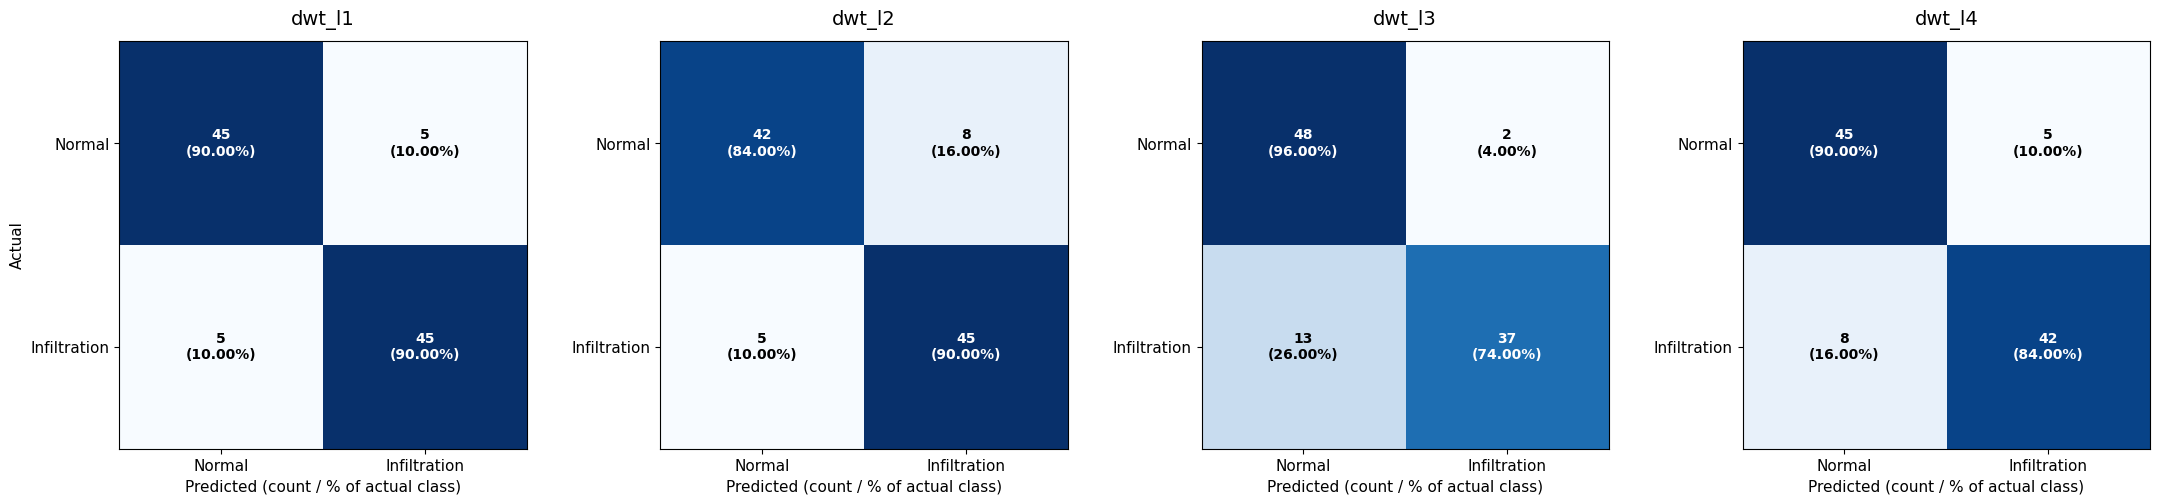

บันทึกภาพ Confusion Matrix เรียบร้อยแล้วที่ 'confusion_matrices_pure_dwt_L1_L4.png'


In [20]:
import os
import cv2
import pywt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# -------------------------------------------------------------
# 1. ฟังก์ชัน DWT กรองสัญญาณรบกวนความถี่สูง (Wavelet: db1)
# -------------------------------------------------------------
dwt_threshold_ratios = {'L1': 0.05, 'L2': 0.10, 'L3': 0.20, 'L4': 0.35}

def apply_pure_dwt(img_gray_np, thresh_ratio=0.10):
    """แยกย่อยความถี่ด้วย 2D DWT และทำ Soft Thresholding บนรายละเอียดย่อย"""
    coeffs2 = pywt.dwt2(img_gray_np.astype(np.float32), 'db1')
    LL, (LH, HL, HH) = coeffs2

    # คำนวณขีดแบ่งเกณฑ์ (Threshold) จากค่าสัมประสิทธิ์สูงสุด
    max_coeff = np.max([np.abs(LH), np.abs(HL), np.abs(HH)])
    threshold = thresh_ratio * max_coeff

    # กรองความถี่สูงด้วย Soft Thresholding
    LH_t = pywt.threshold(LH, threshold, mode='soft')
    HL_t = pywt.threshold(HL, threshold, mode='soft')
    HH_t = pywt.threshold(HH, threshold, mode='soft')

    # สังเคราะห์ภาพย้อนกลับ (Inverse DWT)
    recon = pywt.idwt2((LL, (LH_t, HL_t, HH_t)), 'db1')
    return np.clip(recon, 0, 255).astype(np.uint8)

# -------------------------------------------------------------
# 2. Pre-process และบันทึกภาพลงแคช (Offline Caching)
# -------------------------------------------------------------
def cache_dwt_dataset(df_subset, subset_name):
    for lvl in ['L1', 'L2', 'L3', 'L4']:
        os.makedirs(f"/content/dwt_cache/{subset_name}/{lvl}", exist_ok=True)

    print(f"กำลังบันทึกแคช DWT สำหรับชุด {subset_name} ({len(df_subset)} ภาพ)...")
    for _, row in df_subset.iterrows():
        img_id = row['image_id']
        img_gray = cv2.imread(row['img_path'], cv2.IMREAD_GRAYSCALE)
        img_resized = cv2.resize(img_gray, (224, 224))

        for lvl, tr in dwt_threshold_ratios.items():
            denoised_dwt = apply_pure_dwt(img_resized, thresh_ratio=tr)
            save_path = f"/content/dwt_cache/{subset_name}/{lvl}/{img_id}.png"
            cv2.imwrite(save_path, denoised_dwt)

cache_dwt_dataset(train_df, "train")
cache_dwt_dataset(test_df, "test")
print("แคชชุดข้อมูล DWT L1 - L4 เสร็จสมบูรณ์!\n")

# -------------------------------------------------------------
# 3. Custom Dataset สำหรับอ่านภาพจากแคช DWT
# -------------------------------------------------------------
class CachedDWTCXRDataset(Dataset):
    def __init__(self, dataframe, subset_name="train", level='L1', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.subset_name = subset_name
        self.level = level
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_id = self.df.loc[idx, 'image_id']
        cached_path = f"/content/dwt_cache/{self.subset_name}/{self.level}/{img_id}.png"
        image = Image.open(cached_path).convert('RGB')
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# -------------------------------------------------------------
# 4. ฝึกสอน ResNet-50 เปรียบเทียบ DWT (L1 - L4)
# -------------------------------------------------------------
filter_levels = ['L1', 'L2', 'L3', 'L4']
results = []
confusion_matrices = {}

print("========================================================")
print(" เริ่มการทดลองฝึกสอน Pure DWT Pipeline (L1 - L4)")
print("========================================================")

for level in filter_levels:
    print(f"\n>>> [กำลังเริ่มการทดลอง: Pure DWT {level}] <<<")

    lvl_train_loader = DataLoader(
        CachedDWTCXRDataset(train_df, "train", level=level, transform=train_transform),
        batch_size=32, shuffle=True, num_workers=2
    )
    lvl_test_loader = DataLoader(
        CachedDWTCXRDataset(test_df, "test", level=level, transform=val_test_transform),
        batch_size=32, shuffle=False, num_workers=2
    )

    # ควบคุมตัวแปรให้เป็น Fair Comparison (ResNet-50 Fixed Backbone)
    lvl_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    lvl_model.fc = nn.Linear(lvl_model.fc.in_features, 2)
    lvl_model = lvl_model.to(device)

    lvl_criterion = nn.CrossEntropyLoss()
    lvl_optimizer = torch.optim.Adam(lvl_model.parameters(), lr=1e-4)

    # ฝึกสอน 7 Epochs
    lvl_model.train()
    for epoch in range(7):
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in lvl_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            lvl_optimizer.zero_grad()
            outputs = lvl_model(imgs)
            loss = lvl_criterion(outputs, lbls)
            loss.backward()
            lvl_optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == lbls.data).item()
            total += lbls.size(0)

        if (epoch + 1) in [1, 4, 7]:
            print(f"Epoch [{epoch+1:02d}/07] Loss: {running_loss/total:.4f} | Train Acc: {correct/total:.4f}")

    # บันทึก Checkpoint
    save_name = f"dwt_{level.lower()}_resnet50.pth"
    torch.save(lvl_model.state_dict(), save_name)

    # ทดสอบบน Balanced Test Set 100 ภาพ
    lvl_model.eval()
    all_preds, all_targets, all_probs = [], [], []
    with torch.no_grad():
        for imgs, lbls in lvl_test_loader:
            imgs = imgs.to(device)
            outputs = lvl_model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(lbls.numpy())

    all_targets = np.array(all_targets)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    roc = roc_auc_score(all_targets, all_probs)

    results.append({
        'สภาวะการทดลอง': f'DWT {level}',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

    confusion_matrices[level] = confusion_matrix(all_targets, all_preds)

# -------------------------------------------------------------
# 5. แสดงผลตารางสรุป Metric ทางการแพทย์
# -------------------------------------------------------------
df_results = pd.DataFrame(results)
print("\n" + "="*70)
print(" สรุปผลการประเมินการจำแนกโรคกลุ่ม Pure DWT (L1 - L4)")
print("="*70)
display(df_results.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))

# -------------------------------------------------------------
# 6. พล็อต Confusion Matrices 4 ช่อง
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_labels = ['Normal', 'Infiltration']

for idx, level in enumerate(filter_levels):
    cm = confusion_matrices[level]
    ax = axes[idx]

    ax.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    ax.set_title(f'dwt_{level.lower()}', fontsize=14, pad=12)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels, fontsize=11)
    ax.set_yticklabels(class_labels, fontsize=11)
    ax.set_xlabel('Predicted (count / % of actual class)', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Actual', fontsize=11)

    for i in range(2):
        row_sum = cm[i].sum()
        for j in range(2):
            count = cm[i, j]
            pct = (count / row_sum * 100) if row_sum > 0 else 0
            text_color = "white" if count > (cm.max() / 2) else "black"
            ax.text(j, i, f"{count}\n({pct:.2f}%)", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices_pure_dwt_L1_L4.png', dpi=300)
plt.show()
print("บันทึกภาพ Confusion Matrix เรียบร้อยแล้วที่ 'confusion_matrices_pure_dwt_L1_L4.png'")

# **โค้ดแสดงภาพแยกย่านความถี่ (ความถี่ต่ำ, กลาง, สูง) ด้วย DWT**

/tmp/ipykernel_2373/2866814433.py:64: UserWarning: Glyph 3650 (\N{THAI CHARACTER SARA O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/2866814433.py:64: UserWarning: Glyph 3588 (\N{THAI CHARACTER KHO KHWAI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/2866814433.py:64: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/2866814433.py:64: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/2866814433.py:64: UserWarning: Glyph 3626 (\N{THAI CHARACTER SO SUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/2866814433.py:64: UserWarning: Glyph 3657 (\N{THAI CHARACTER MAI THO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/2866814433.py:64: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.


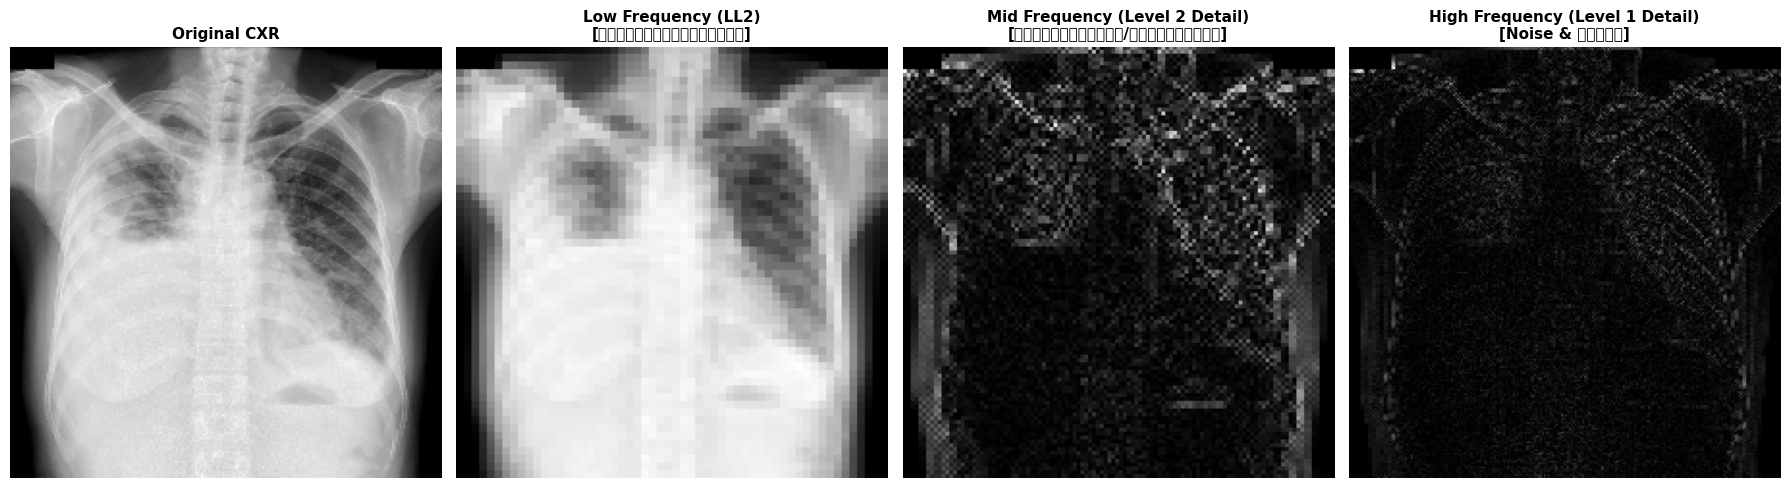

บันทึกภาพแยกย่านความถี่เรียบร้อยแล้วที่ 'dwt_frequency_bands.png'


In [21]:
import cv2
import pywt
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. ฟังก์ชันแยกภาพออกเป็น 3 ย่านความถี่ด้วย 2-Level DWT (Wavelet: db1)
def decompose_frequency_bands(img_gray, wavelet='db1'):
    img_f = img_gray.astype(np.float32)

    # เลเวล 1: แยกความถี่ต่ำ (LL1) กับ ความถี่สูง (LH1, HL1, HH1)
    coeffs1 = pywt.dwt2(img_f, wavelet)
    LL1, (LH1, HL1, HH1) = coeffs1

    # เลเวล 2: นำ LL1 มาแยกต่อ ได้ความถี่ต่ำสุด (LL2) และ ความถี่กลาง (LH2, HL2, HH2)
    coeffs2 = pywt.dwt2(LL1, wavelet)
    LL2, (LH2, HL2, HH2) = coeffs2

    # --- สังเคราะห์ภาพเฉพาะย่านความถี่ (Reconstruction) ---
    # 1. ความถี่ต่ำ (Low Frequency): เก็บเฉพาะ LL2, ตัดย่านอื่นเป็น 0 ทั้งหมด
    zeros_mid = (np.zeros_like(LH2), np.zeros_like(HL2), np.zeros_like(HH2))
    zeros_high = (np.zeros_like(LH1), np.zeros_like(HL1), np.zeros_like(HH1))

    rec_ll1_from_low = pywt.idwt2((LL2, zeros_mid), wavelet)
    low_freq_img = pywt.idwt2((rec_ll1_from_low, zeros_high), wavelet)

    # 2. ความถี่กลาง (Mid Frequency): เก็บเฉพาะ (LH2, HL2, HH2), ให้ LL2 เป็น 0
    rec_ll1_from_mid = pywt.idwt2((np.zeros_like(LL2), (LH2, HL2, HH2)), wavelet)
    mid_freq_img = pywt.idwt2((rec_ll1_from_mid, zeros_high), wavelet)

    # 3. ความถี่สูง (High Frequency): เก็บเฉพาะ (LH1, HL1, HH1), ให้ LL1 เป็น 0
    high_freq_img = pywt.idwt2((np.zeros_like(LL1), (LH1, HL1, HH1)), wavelet)

    return low_freq_img, mid_freq_img, high_freq_img

# 2. โหลดภาพตัวอย่างเอกซเรย์
sample_path = train_df.iloc[0]['img_path']
raw_img = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)
raw_img = cv2.resize(raw_img, (224, 224))

low_band, mid_band, high_band = decompose_frequency_bands(raw_img, wavelet='db1')

# 3. พล็อตกราฟิกเปรียบเทียบแต่ละย่านความถี่
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
titles = [
    'Original CXR',
    'Low Frequency (LL2)\n[โครงสร้างปอดหลัก]',
    'Mid Frequency (Level 2 Detail)\n[ขอบเขตรอยโรค/เนื้อเยื่อ]',
    'High Frequency (Level 1 Detail)\n[Noise & ขอบคม]'
]
imgs = [raw_img, low_band, mid_band, high_band]

for ax, img, title in zip(axes, imgs, titles):
    # ปรับสเกลภาพความถี่กลางและสูงเพื่อให้เห็นโครงสร้างชัดเจนขึ้นบนจอ
    disp = img.copy()
    if title != titles[0] and title != titles[1]:
        disp = np.abs(disp)
        disp = (disp / (disp.max() + 1e-8)) * 255.0

    ax.imshow(disp, cmap='gray')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('dwt_frequency_bands.png', dpi=300)
plt.show()
print("บันทึกภาพแยกย่านความถี่เรียบร้อยแล้วที่ 'dwt_frequency_bands.png'")

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3616 (\N{THAI CHARACTER PHO SAMPHAO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3614 (\N{THAI CHARACTER PHO PHAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3606 (\N{THAI CHARACTER THO THUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3637 (\N{THAI CHARACTER SARA II}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(byte

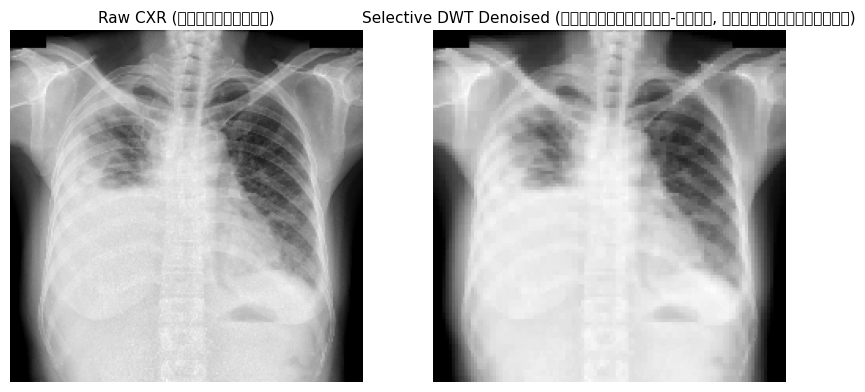

In [22]:
def selective_dwt_denoise(img_gray, high_thresh_ratio=0.15, mid_thresh_ratio=0.03):
    """กรองความถี่สูงเป็นหลัก และกรองความถี่กลางเพียงเล็กน้อยเพื่อรักษารอยฝ้า"""
    coeffs1 = pywt.dwt2(img_gray.astype(np.float32), 'db1')
    LL1, (LH1, HL1, HH1) = coeffs1

    coeffs2 = pywt.dwt2(LL1, 'db1')
    LL2, (LH2, HL2, HH2) = coeffs2

    # 1. Soft thresholding บนความถี่สูง (LH1, HL1, HH1) แบบเข้มงวด
    th_high = high_thresh_ratio * np.max([np.abs(LH1), np.abs(HL1), np.abs(HH1)])
    LH1_f = pywt.threshold(LH1, th_high, mode='soft')
    HL1_f = pywt.threshold(HL1, th_high, mode='soft')
    HH1_f = pywt.threshold(HH1, th_high, mode='soft')

    # 2. Soft thresholding บนความถี่กลาง (LH2, HL2, HH2) แบบเบาบาง
    th_mid = mid_thresh_ratio * np.max([np.abs(LH2), np.abs(HL2), np.abs(HH2)])
    LH2_f = pywt.threshold(LH2, th_mid, mode='soft')
    HL2_f = pywt.threshold(HL2, th_mid, mode='soft')
    HH2_f = pywt.threshold(HH2, th_mid, mode='soft')

    # 3. สังเคราะห์ภาพคืน (Inverse DWT)
    LL1_recon = pywt.idwt2((LL2, (LH2_f, HL2_f, HH2_f)), 'db1')
    denoised_img = pywt.idwt2((LL1_recon, (LH1_f, HL1_f, HH1_f)), 'db1')

    return np.clip(denoised_img, 0, 255).astype(np.uint8)

# ทดสอบแสดงผลภาพที่ผ่านการกรองความถี่สูง
denoised_result = selective_dwt_denoise(raw_img)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(raw_img, cmap='gray')
plt.title("Raw CXR (ภาพตั้งต้น)", fontsize=11)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(denoised_result, cmap='gray')
plt.title("Selective DWT Denoised (คงความถี่ต่ำ-กลาง, กรองความถี่สูง)", fontsize=11)
plt.axis('off')
plt.show()

กำลังประมวลผลแยกย่านความถี่ชุด train (400 ภาพ)...
กำลังประมวลผลแยกย่านความถี่ชุด test (100 ภาพ)...
แคชไฟล์ย่านความถี่ทั้งหมดเรียบร้อยแล้ว!

 เริ่มการทดลองฝึกสอน ResNet-50 บน DWT Frequency Bands

>>> [กำลังเริ่มการทดลอง: ย่านความถี่ low_only] <<<
Epoch [01/07] Loss: 0.6718 | Train Acc: 0.6225
Epoch [04/07] Loss: 0.2151 | Train Acc: 0.9250
Epoch [07/07] Loss: 0.0351 | Train Acc: 1.0000

>>> [กำลังเริ่มการทดลอง: ย่านความถี่ mid_only] <<<
Epoch [01/07] Loss: 0.6814 | Train Acc: 0.5625
Epoch [04/07] Loss: 0.2735 | Train Acc: 0.9475
Epoch [07/07] Loss: 0.0495 | Train Acc: 0.9925

>>> [กำลังเริ่มการทดลอง: ย่านความถี่ high_only] <<<
Epoch [01/07] Loss: 0.6840 | Train Acc: 0.6050
Epoch [04/07] Loss: 0.2512 | Train Acc: 0.9575
Epoch [07/07] Loss: 0.0492 | Train Acc: 0.9800

>>> [กำลังเริ่มการทดลอง: ย่านความถี่ selective] <<<
Epoch [01/07] Loss: 0.6686 | Train Acc: 0.6200
Epoch [04/07] Loss: 0.1356 | Train Acc: 0.9800
Epoch [07/07] Loss: 0.0420 | Train Acc: 0.9925

 สรุปผลการประเมินการจำแนกโรคแยก

,สภาวะย่านความถี่,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,low_only,0.8500,0.8302,0.8800,0.8544,0.9352
1,mid_only,0.7800,0.8889,0.6400,0.7442,0.8868
2,high_only,0.8000,0.8125,0.7800,0.7959,0.8920
3,selective,0.7900,1.0000,0.5800,0.7342,0.9212


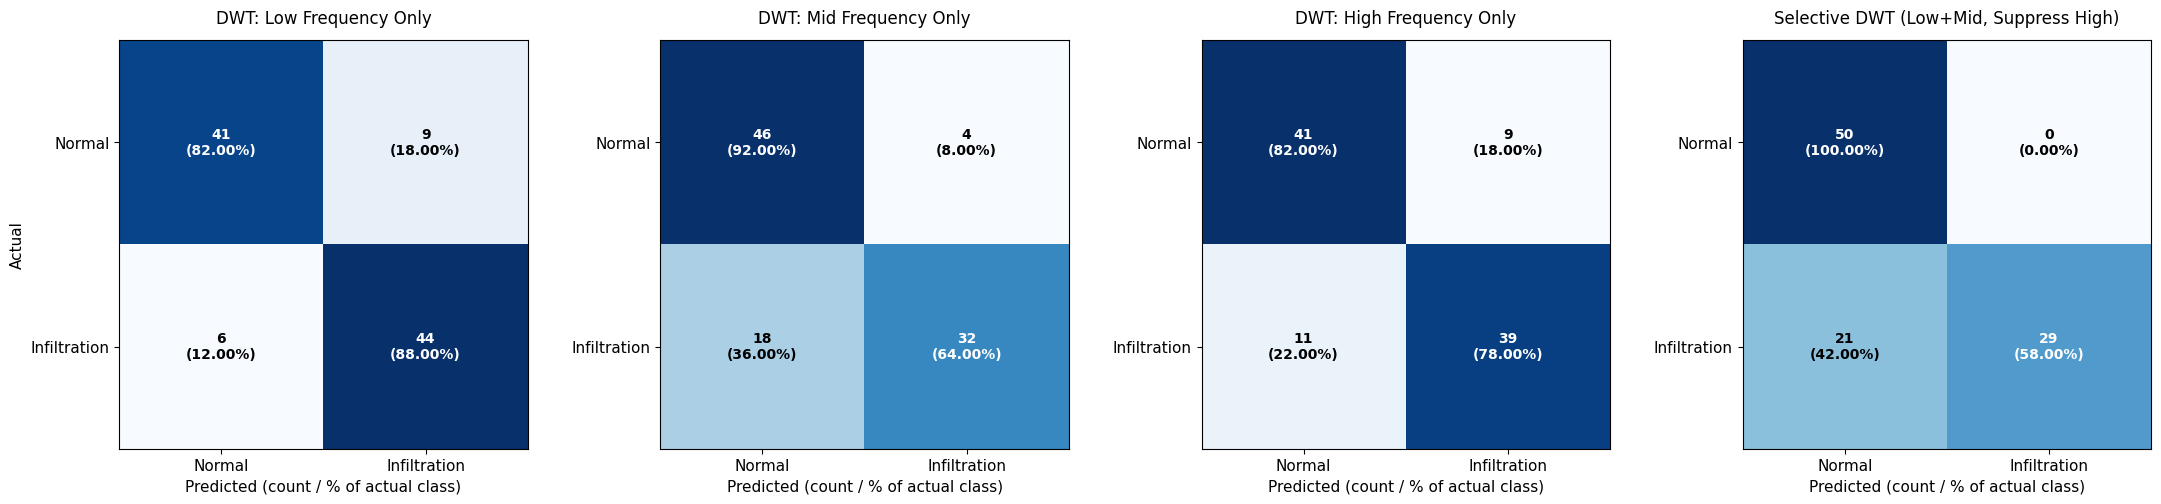

บันทึกภาพ Confusion Matrix ที่ 'confusion_matrices_dwt_frequencies.png'


In [23]:
import os
import cv2
import pywt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# -------------------------------------------------------------
# 1. ฟังก์ชันแยกและสังเคราะห์ภาพตามย่านความถี่ (Wavelet: db1)
# -------------------------------------------------------------
def process_dwt_band(img_gray, condition='selective'):
    img_f = img_gray.astype(np.float32)
    wavelet = 'db1'

    # Level 1 Decomposition
    coeffs1 = pywt.dwt2(img_f, wavelet)
    LL1, (LH1, HL1, HH1) = coeffs1

    # Level 2 Decomposition
    coeffs2 = pywt.dwt2(LL1, wavelet)
    LL2, (LH2, HL2, HH2) = coeffs2

    zeros_mid = (np.zeros_like(LH2), np.zeros_like(HL2), np.zeros_like(HH2))
    zeros_high = (np.zeros_like(LH1), np.zeros_like(HL1), np.zeros_like(HH1))

    if condition == 'low_only':
        # เก็บเฉพาะ Low Frequency (LL2)
        rec_ll1 = pywt.idwt2((LL2, zeros_mid), wavelet)
        recon = pywt.idwt2((rec_ll1, zeros_high), wavelet)

    elif condition == 'mid_only':
        # เก็บเฉพาะ Mid Frequency (LH2, HL2, HH2)
        rec_ll1 = pywt.idwt2((np.zeros_like(LL2), (LH2, HL2, HH2)), wavelet)
        recon = pywt.idwt2((rec_ll1, zeros_high), wavelet)
        recon = np.abs(recon)
        recon = (recon / (recon.max() + 1e-8)) * 255.0

    elif condition == 'high_only':
        # เก็บเฉพาะ High Frequency (LH1, HL1, HH1)
        recon = pywt.idwt2((np.zeros_like(LL1), (LH1, HL1, HH1)), wavelet)
        recon = np.abs(recon)
        recon = (recon / (recon.max() + 1e-8)) * 255.0

    elif condition == 'selective':
        # คง Low + Mid, Soft Thresholding เฉพาะ High Frequency
        th_high = 0.15 * np.max([np.abs(LH1), np.abs(HL1), np.abs(HH1)])
        LH1_f = pywt.threshold(LH1, th_high, mode='soft')
        HL1_f = pywt.threshold(HL1, th_high, mode='soft')
        HH1_f = pywt.threshold(HH1, th_high, mode='soft')

        LL1_recon = pywt.idwt2((LL2, (LH2, HL2, HH2)), wavelet)
        recon = pywt.idwt2((LL1_recon, (LH1_f, HL1_f, HH1_f)), wavelet)

    return np.clip(recon, 0, 255).astype(np.uint8)

# -------------------------------------------------------------
# 2. ทำแคชบันทึกไฟล์ภาพล่วงหน้า
# -------------------------------------------------------------
freq_conditions = ['low_only', 'mid_only', 'high_only', 'selective']

def cache_freq_dataset(df_subset, subset_name):
    for cond in freq_conditions:
        os.makedirs(f"/content/dwt_freq_cache/{subset_name}/{cond}", exist_ok=True)

    print(f"กำลังประมวลผลแยกย่านความถี่ชุด {subset_name} ({len(df_subset)} ภาพ)...")
    for _, row in df_subset.iterrows():
        img_id = row['image_id']
        img_gray = cv2.imread(row['img_path'], cv2.IMREAD_GRAYSCALE)
        img_resized = cv2.resize(img_gray, (224, 224))

        for cond in freq_conditions:
            processed = process_dwt_band(img_resized, condition=cond)
            save_path = f"/content/dwt_freq_cache/{subset_name}/{cond}/{img_id}.png"
            cv2.imwrite(save_path, processed)

cache_freq_dataset(train_df, "train")
cache_freq_dataset(test_df, "test")
print("แคชไฟล์ย่านความถี่ทั้งหมดเรียบร้อยแล้ว!\n")

# -------------------------------------------------------------
# 3. Custom Dataset สำหรับอ่านจากแคชย่านความถี่
# -------------------------------------------------------------
class CachedDWTFreqDataset(Dataset):
    def __init__(self, dataframe, subset_name="train", condition='selective', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.subset_name = subset_name
        self.condition = condition
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_id = self.df.loc[idx, 'image_id']
        cached_path = f"/content/dwt_freq_cache/{self.subset_name}/{self.condition}/{img_id}.png"
        image = Image.open(cached_path).convert('RGB')
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# -------------------------------------------------------------
# 4. ลูปทดลองฝึกสอน ResNet-50 เปรียบเทียบ 4 ย่านความถี่
# -------------------------------------------------------------
results = []
confusion_matrices = {}

print("========================================================")
print(" เริ่มการทดลองฝึกสอน ResNet-50 บน DWT Frequency Bands")
print("========================================================")

for cond in freq_conditions:
    print(f"\n>>> [กำลังเริ่มการทดลอง: ย่านความถี่ {cond}] <<<")

    lvl_train_loader = DataLoader(
        CachedDWTFreqDataset(train_df, "train", condition=cond, transform=train_transform),
        batch_size=32, shuffle=True, num_workers=2
    )
    lvl_test_loader = DataLoader(
        CachedDWTFreqDataset(test_df, "test", condition=cond, transform=val_test_transform),
        batch_size=32, shuffle=False, num_workers=2
    )

    lvl_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    lvl_model.fc = nn.Linear(lvl_model.fc.in_features, 2)
    lvl_model = lvl_model.to(device)

    lvl_criterion = nn.CrossEntropyLoss()
    lvl_optimizer = torch.optim.Adam(lvl_model.parameters(), lr=1e-4)

    # ฝึกสอน 7 Epochs ภายใต้ตัวแปรควบคุมคงที่
    lvl_model.train()
    for epoch in range(7):
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in lvl_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            lvl_optimizer.zero_grad()
            outputs = lvl_model(imgs)
            loss = lvl_criterion(outputs, lbls)
            loss.backward()
            lvl_optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == lbls.data).item()
            total += lbls.size(0)

        if (epoch + 1) in [1, 4, 7]:
            print(f"Epoch [{epoch+1:02d}/07] Loss: {running_loss/total:.4f} | Train Acc: {correct/total:.4f}")

    # บันทึก Checkpoint
    save_name = f"dwt_freq_{cond}_resnet50.pth"
    torch.save(lvl_model.state_dict(), save_name)

    # ประเมินผลบนชุดทดสอบมาตรฐาน (Balanced Test Set 100 ภาพ)
    lvl_model.eval()
    all_preds, all_targets, all_probs = [], [], []
    with torch.no_grad():
        for imgs, lbls in lvl_test_loader:
            imgs = imgs.to(device)
            outputs = lvl_model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(lbls.numpy())

    all_targets = np.array(all_targets)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    roc = roc_auc_score(all_targets, all_probs)

    results.append({
        'สภาวะย่านความถี่': cond,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

    confusion_matrices[cond] = confusion_matrix(all_targets, all_preds)

# -------------------------------------------------------------
# 5. แสดงตารางผลการจำแนกโรคทางการแพทย์
# -------------------------------------------------------------
df_results = pd.DataFrame(results)
print("\n" + "="*70)
print(" สรุปผลการประเมินการจำแนกโรคแยกตามย่านความถี่ DWT")
print("="*70)
display(df_results.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))

# -------------------------------------------------------------
# 6. พล็อต Confusion Matrices ทั้ง 4 ย่านความถี่
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_labels = ['Normal', 'Infiltration']
display_titles = {
    'low_only': 'DWT: Low Frequency Only',
    'mid_only': 'DWT: Mid Frequency Only',
    'high_only': 'DWT: High Frequency Only',
    'selective': 'Selective DWT (Low+Mid, Suppress High)'
}

for idx, cond in enumerate(freq_conditions):
    cm = confusion_matrices[cond]
    ax = axes[idx]

    ax.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    ax.set_title(display_titles[cond], fontsize=12, pad=12)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels, fontsize=11)
    ax.set_yticklabels(class_labels, fontsize=11)
    ax.set_xlabel('Predicted (count / % of actual class)', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Actual', fontsize=11)

    for i in range(2):
        row_sum = cm[i].sum()
        for j in range(2):
            count = cm[i, j]
            pct = (count / row_sum * 100) if row_sum > 0 else 0
            text_color = "white" if count > (cm.max() / 2) else "black"
            ax.text(j, i, f"{count}\n({pct:.2f}%)", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices_dwt_frequencies.png', dpi=300)
plt.show()
print("บันทึกภาพ Confusion Matrix ที่ 'confusion_matrices_dwt_frequencies.png'")

# **โค้ดสำหรับเริ่มทดลองต่อ: สกัด Grad-CAM และพล็อตเทียบกับ Bounding Box**

/tmp/ipykernel_2373/3440085366.py:77: UserWarning: Glyph 3616 (\N{THAI CHARACTER PHO SAMPHAO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/3440085366.py:77: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/3440085366.py:77: UserWarning: Glyph 3614 (\N{THAI CHARACTER PHO PHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/3440085366.py:77: UserWarning: Glyph 3605 (\N{THAI CHARACTER TO TAO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/3440085366.py:77: UserWarning: Glyph 3633 (\N{THAI CHARACTER MAI HAN-AKAT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/3440085366.py:77: UserWarning: Glyph 3657 (\N{THAI CHARACTER MAI THO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2373/3440085366.py:77: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) Dej

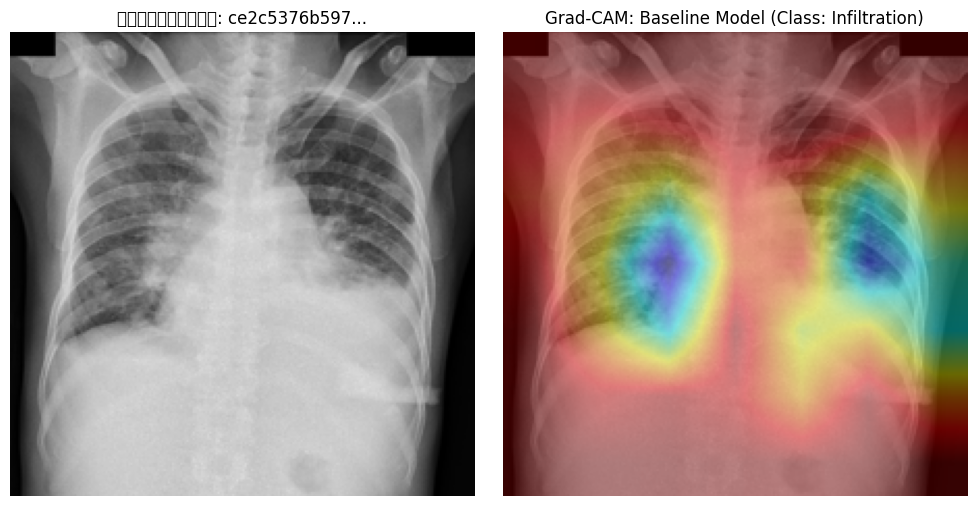

In [24]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

# 1. คลาสสกัด Grad-CAM สำหรับ ResNet-50
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Hook สำหรับดึง Feature Map และ Gradients
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, target_class=1):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()

        # คำนวณ Backward เฉพาะ Class ที่ต้องการ (Infiltration = 1)
        loss = output[0, target_class]
        loss.backward()

        # คำนวณ GAP ของ Gradients เพื่อใช้เป็น Weights
        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze()
        cam = F.relu(cam) # รักษาเฉพาะค่าที่เป็นบวก

        cam = cam.detach().cpu().numpy()
        cam = cv2.resize(cam, (224, 224))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

# 2. โหลดโมเดล Baseline และ DAE+CLAHE มาเปรียบเทียบ
model_baseline = models.resnet50()
model_baseline.fc = nn.Linear(model_baseline.fc.in_features, 2)
model_baseline.load_state_dict(torch.load('baseline_resnet50.pth'))
model_baseline = model_baseline.to(device)

# เลเยอร์สุดท้ายของ ResNet-50 สำหรับดึง Heatmap
cam_baseline = GradCAM(model_baseline, model_baseline.layer4[-1])

# 3. สุ่มเลือกภาพเคส Infiltration มาแสดงผล Heatmap
sample_row = test_df[test_df['target'] == 1].iloc[0]
raw_img = Image.open(sample_row['img_path']).convert('RGB').resize((224, 224))
input_tensor = val_test_transform(raw_img).unsqueeze(0).to(device)

heatmap_base = cam_baseline.generate_heatmap(input_tensor, target_class=1)

# ซ้อนทับ Heatmap ลงบนภาพเอกซเรย์
heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_base), cv2.COLORMAP_JET)
overlay = cv2.addWeighted(np.array(raw_img), 0.6, heatmap_color, 0.4, 0)

# 4. พล็อตผลลัพธ์
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(raw_img)
plt.title(f"ภาพตั้งต้น: {sample_row['image_id'][:12]}...")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(overlay)
plt.title("Grad-CAM: Baseline Model (Class: Infiltration)")
plt.axis('off')

plt.tight_layout()
plt.show()

In [25]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image

# 1. คลาสสกัด Grad-CAM สำหรับ ResNet-50
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, target_class=1):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()

        loss = output[0, target_class]
        loss.backward()

        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze()
        cam = F.relu(cam)

        cam = cam.detach().cpu().numpy()
        cam = cv2.resize(cam, (224, 224))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

# 2. เตรียมรายการโมเดลทั้งหมด (ทั้ง 10 สภาวะเดิม + สภาวะที่ทดลองเพิ่ม)
model_experiments = {
    # กลุ่มตั้งต้นตามเล่มข้อเสนอโครงงาน (10 สภาวะ)
    'Baseline (Raw CXR)': 'baseline_resnet50.pth',
    'Median Filter L1': 'median_l1_resnet50.pth',
    'Median Filter L2': 'median_l2_resnet50.pth',
    'Median Filter L3': 'median_l3_resnet50.pth',
    'CLAHE + DWT L1': 'clahe_dwt_l1_resnet50.pth',
    'CLAHE + DWT L2': 'clahe_dwt_l2_resnet50.pth',
    'CLAHE + DWT L3': 'clahe_dwt_l3_resnet50.pth',
    'DAE + CLAHE L1': 'dae_clahe_l1_resnet50.pth',
    'DAE + CLAHE L2': 'dae_clahe_l2_resnet50.pth',
    'DAE + CLAHE L3 (Proposed)': 'dae_clahe_l3_resnet50.pth',

    # กลุ่มที่ทดลองเพิ่มเติม (Ablation Study: Pure DWT L1 - L4)
    'Pure DWT L1': 'dwt_l1_resnet50.pth',
    'Pure DWT L2': 'dwt_l2_resnet50.pth',
    'Pure DWT L3': 'dwt_l3_resnet50.pth',
    'Pure DWT L4': 'dwt_l4_resnet50.pth',

    # กลุ่มที่ทดลองเพิ่มเติม (DWT Frequency Bands)
    'DWT Low Frequency Only': 'dwt_freq_low_only_resnet50.pth',
    'DWT Mid Frequency Only': 'dwt_freq_mid_only_resnet50.pth',
    'DWT High Frequency Only': 'dwt_freq_high_only_resnet50.pth',
    'Selective DWT': 'dwt_freq_selective_resnet50.pth'
}

# 3. โหลดชุดข้อมูล Ground-Truth Bounding Box สำหรับ Infiltration
# คัดกรองภาพ Infiltration จาก Metadata เดิมที่มีพิกัด x_min, y_min, x_max, y_max
df_infilt_boxes = df[df['class_name'] == 'Infiltration'].dropna(subset=['x_min', 'y_min', 'x_max', 'y_max']).copy()
df_infilt_boxes = df_infilt_boxes.drop_duplicates(subset=['image_id']).reset_index(drop=True)

print(f"พบภาพที่มี Ground-Truth Bounding Box สำหรับประเมิน XAI: {len(df_infilt_boxes)} ภาพ")

# 4. ฟังก์ชันประเมิน XAI Metrics
xai_summary = []

for cond_name, weight_file in model_experiments.items():
    if not os.path.exists(weight_file):
        print(f"ข้าม {cond_name} (ไม่พบไฟล์ {weight_file})")
        continue

    print(f"กำลังประเมิน XAI: {cond_name}...")

    # โหลดโมเดล ResNet-50
    eval_model = models.resnet50()
    eval_model.fc = nn.Linear(eval_model.fc.in_features, 2)
    eval_model.load_state_dict(torch.load(weight_file, map_location=device))
    eval_model = eval_model.to(device)

    grad_cam = GradCAM(eval_model, eval_model.layer4[-1])

    hits = 0
    total_energy_ratio = []
    valid_cases = 0

    for _, row in df_infilt_boxes.iterrows():
        img_p = os.path.join(train_dir, f"{row['image_id']}.png")
        if not os.path.exists(img_p):
            continue

        orig_img = Image.open(img_p).convert('RGB')
        orig_w, orig_h = orig_img.size

        # ปรับสัดส่วนพิกัด Bounding Box ให้เข้ากับขนาด 224x224
        bx_min = int((row['x_min'] / orig_w) * 224)
        by_min = int((row['y_min'] / orig_h) * 224)
        bx_max = int((row['x_max'] / orig_w) * 224)
        by_max = int((row['y_max'] / orig_h) * 224)

        input_t = val_test_transform(orig_img).unsqueeze(0).to(device)
        cam = grad_cam.generate_heatmap(input_t, target_class=1)

        # 4.1 Pointing Game: จุดสูงสุดตกใน Bounding Box หรือไม่
        max_idx = np.unravel_index(np.argmax(cam), cam.shape)
        max_y, max_x = max_idx[0], max_idx[1]

        if (bx_min <= max_x <= bx_max) and (by_min <= max_y <= by_max):
            hits += 1

        # 4.2 Saliency Energy: สัดส่วนพลังงานในกรอบเทียบกับพลังงานรวม
        box_energy = np.sum(cam[by_min:by_max, bx_min:bx_max])
        total_energy = np.sum(cam) + 1e-8
        total_energy_ratio.append(box_energy / total_energy)
        valid_cases += 1

    hit_rate = (hits / valid_cases * 100) if valid_cases > 0 else 0
    mean_energy = (np.mean(total_energy_ratio) * 100) if valid_cases > 0 else 0

    xai_summary.append({
        'สภาวะการทดลอง (Condition)': cond_name,
        'Grad-CAM Hit Rate (%)': f"{hit_rate:.2f}%",
        'Grad-CAM Energy Inside Box (%)': f"{mean_energy:.2f}%"
    })

# 5. แสดงผลตารางสรุป XAI เปรียบเทียบทุกสภาวะ (ทั้งของเดิมและที่ทำเพิ่ม)
df_xai_table = pd.DataFrame(xai_summary)
print("\n" + "="*80)
print(" ตารางสรุปการประเมิน XAI Quantitative Localization (เปรียบเทียบทุกวิธี)")
print("="*80)
display(df_xai_table)

พบภาพที่มี Ground-Truth Bounding Box สำหรับประเมิน XAI: 613 ภาพ
กำลังประเมิน XAI: Baseline (Raw CXR)...
กำลังประเมิน XAI: Median Filter L1...
กำลังประเมิน XAI: Median Filter L2...
กำลังประเมิน XAI: Median Filter L3...
กำลังประเมิน XAI: CLAHE + DWT L1...
กำลังประเมิน XAI: CLAHE + DWT L2...
กำลังประเมิน XAI: CLAHE + DWT L3...
กำลังประเมิน XAI: DAE + CLAHE L1...
กำลังประเมิน XAI: DAE + CLAHE L2...
กำลังประเมิน XAI: DAE + CLAHE L3 (Proposed)...
กำลังประเมิน XAI: Pure DWT L1...
กำลังประเมิน XAI: Pure DWT L2...
กำลังประเมิน XAI: Pure DWT L3...
กำลังประเมิน XAI: Pure DWT L4...
กำลังประเมิน XAI: DWT Low Frequency Only...
กำลังประเมิน XAI: DWT Mid Frequency Only...
กำลังประเมิน XAI: DWT High Frequency Only...
กำลังประเมิน XAI: Selective DWT...

 ตารางสรุปการประเมิน XAI Quantitative Localization (เปรียบเทียบทุกวิธี)


,สภาวะการทดลอง (Condition),Grad-CAM Hit Rate (%),Grad-CAM Energy Inside Box (%)
0,Baseline (Raw CXR),0.33%,0.25%
1,Median Filter L1,0.49%,0.37%
2,Median Filter L2,0.49%,0.42%
3,Median Filter L3,0.49%,0.65%
4,CLAHE + DWT L1,0.49%,0.44%
5,CLAHE + DWT L2,0.49%,0.65%
6,CLAHE + DWT L3,0.16%,0.20%
7,DAE + CLAHE L1,0.00%,0.10%
8,DAE + CLAHE L2,0.00%,0.04%
9,DAE + CLAHE L3 (Proposed),0.00%,0.01%


# **โค้ดแสดงภาพ SHAP Pixel Attribution รายภาพ**

In [26]:
!pip install -q shap

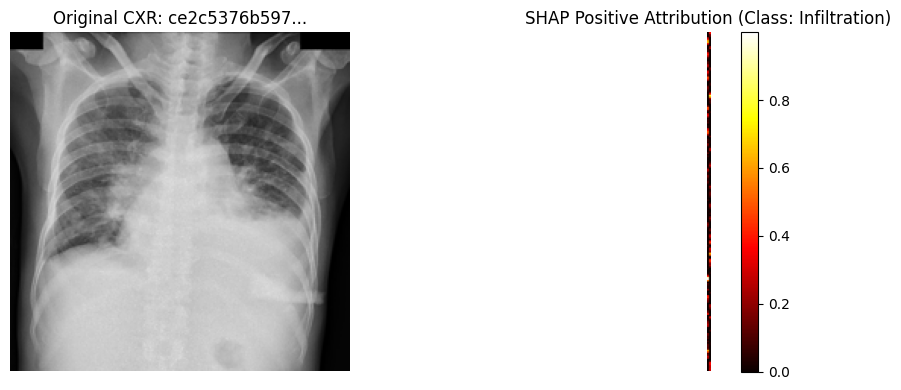

In [27]:
import shap
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. โหลดโมเดล Baseline (หรือโมเดลที่ต้องการเปรียบเทียบ เช่น DAE + CLAHE L3)
model_eval = models.resnet50()
model_eval.fc = nn.Linear(model_eval.fc.in_features, 2)
model_eval.load_state_dict(torch.load('baseline_resnet50.pth', map_location=device))
model_eval = model_eval.to(device)
model_eval.eval()

# 2. เตรียม Background Data สำหรับ GradientExplainer (สุ่ม 20 ภาพจากชุดทดสอบ)
bg_tensors = []
for i in range(min(20, len(test_df))):
    img_p = test_df.iloc[i]['img_path']
    img = Image.open(img_p).convert('RGB')
    bg_tensors.append(val_test_transform(img))
background = torch.stack(bg_tensors).to(device)

# 3. สร้าง Explainer
explainer = shap.GradientExplainer(model_eval, background)

# 4. ทดสอบกับภาพ Infiltration ตัวอย่าง 1 ภาพ
sample_row = test_df[test_df['target'] == 1].iloc[0]
sample_img = Image.open(sample_row['img_path']).convert('RGB')
input_tensor = val_test_transform(sample_img).unsqueeze(0).to(device)

# คำนวณ Shapley values สำหรับ Class 1 (Infiltration)
shap_values, _ = explainer.shap_values(input_tensor, ranked_outputs=2)

# จัดรูปมิติข้อมูลให้อยู่ในรูป (H, W, C) โดยใช้ดัชนี 0 ตามโครงสร้างผลลัพธ์ของ SHAP
shap_img = np.transpose(shap_values[0][0], (1, 2, 0))

# รวมช่องสี RGB เข้าด้วยกันเพื่อดูพิกัดบวก (Positive Attribution)
shap_positive = np.maximum(shap_img.mean(axis=-1), 0)
shap_positive = (shap_positive - shap_positive.min()) / (shap_positive.max() - shap_positive.min() + 1e-8)

# 5. พล็อตเปรียบเทียบภาพดิบกับ SHAP Saliency
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_img.resize((224, 224)))
plt.title(f"Original CXR: {sample_row['image_id'][:12]}...")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(shap_positive, cmap='hot')
plt.title("SHAP Positive Attribution (Class: Infiltration)")
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()

In [28]:
# รายชื่อโมเดลทั้งหมดที่จะประเมิน SHAP
model_experiments = {
    'Baseline (Raw CXR)': 'baseline_resnet50.pth',
    'Median Filter L1': 'median_l1_resnet50.pth',
    'Median Filter L2': 'median_l2_resnet50.pth',
    'Median Filter L3': 'median_l3_resnet50.pth',
    'CLAHE + DWT L1': 'clahe_dwt_l1_resnet50.pth',
    'CLAHE + DWT L2': 'clahe_dwt_l2_resnet50.pth',
    'CLAHE + DWT L3': 'clahe_dwt_l3_resnet50.pth',
    'DAE + CLAHE L1': 'dae_clahe_l1_resnet50.pth',
    'DAE + CLAHE L2': 'dae_clahe_l2_resnet50.pth',
    'DAE + CLAHE L3 (Proposed)': 'dae_clahe_l3_resnet50.pth',
    'Pure DWT L1': 'dwt_l1_resnet50.pth',
    'Pure DWT L2': 'dwt_l2_resnet50.pth',
    'Pure DWT L3': 'dwt_l3_resnet50.pth',
    'Pure DWT L4': 'dwt_l4_resnet50.pth',
    'DWT Low Frequency Only': 'dwt_freq_low_only_resnet50.pth',
    'DWT Mid Frequency Only': 'dwt_freq_mid_only_resnet50.pth',
    'DWT High Frequency Only': 'dwt_freq_high_only_resnet50.pth',
    'Selective DWT': 'dwt_freq_selective_resnet50.pth'
}

shap_summary = []

print("================================================================")
print(" เริ่มการประเมิน SHAP Quantitative Metrics (Hit Rate & Energy)")
print("================================================================")

# คัดกรองเคส Infiltration ที่มี Bounding Box
df_eval_boxes = df_infilt_boxes.copy()

for cond_name, weight_file in model_experiments.items():
    if not os.path.exists(weight_file):
        continue

    print(f"กำลังประเมิน SHAP สำหรับ: {cond_name}...")

    # โหลดโมเดล
    m = models.resnet50()
    m.fc = nn.Linear(m.fc.in_features, 2)
    m.load_state_dict(torch.load(weight_file, map_location=device))
    m = m.to(device)
    m.eval()

    explainer = shap.GradientExplainer(m, background)

    hits = 0
    energy_ratios = []
    valid_count = 0

    for _, row in df_eval_boxes.iterrows():
        img_p = os.path.join(train_dir, f"{row['image_id']}.png")
        if not os.path.exists(img_p):
            continue

        orig_img = Image.open(img_p).convert('RGB')
        orig_w, orig_h = orig_img.size

        # แปลงพิกัด Bounding Box เป็นสเกล 224x224
        bx_min = int((row['x_min'] / orig_w) * 224)
        by_min = int((row['y_min'] / orig_h) * 224)
        bx_max = int((row['x_max'] / orig_w) * 224)
        by_max = int((row['y_max'] / orig_h) * 224)

        inp_t = val_test_transform(orig_img).unsqueeze(0).to(device)

        try:
            # คำนวณ Shapley values
            s_vals, _ = explainer.shap_values(inp_t, ranked_outputs=2)
            s_target = s_vals[0] if isinstance(s_vals, list) else s_vals
            shap_map = np.transpose(s_target[0], (1, 2, 0)).mean(axis=-1)
            # สนใจเฉพาะ Positive Attribution (พิกเซลที่โหวตให้เป็นโรค)
            shap_pos = np.maximum(shap_map, 0)

            # 1. Pointing Game Hit: ตำแหน่งพิกเซลที่มี attribution สูงสุดอยู่ใน BBox หรือไม่
            max_idx = np.unravel_index(np.argmax(shap_pos), shap_pos.shape)
            if (bx_min <= max_idx[1] <= bx_max) and (by_min <= max_idx[0] <= by_max):
                hits += 1

            # 2. Saliency Energy Inside Box: สัดส่วนคะแนนรวมในกล่องเทียบกับทั้งภาพ
            box_energy = np.sum(shap_pos[by_min:by_max, bx_min:bx_max])
            total_energy = np.sum(shap_pos) + 1e-8
            energy_ratios.append(box_energy / total_energy)
            valid_count += 1
        except Exception:
            continue

    hit_rate = (hits / valid_count * 100) if valid_count > 0 else 0
    mean_energy = (np.mean(energy_ratios) * 100) if valid_count > 0 else 0

    shap_summary.append({
        'สภาวะการทดลอง': cond_name,
        'SHAP Hit Rate (%)': f"{hit_rate:.2f}%",
        'SHAP Energy Inside Box (%)': f"{mean_energy:.2f}%"
    })

# แสดงผลตารางสรุป
df_shap_results = pd.DataFrame(shap_summary)
print("\n" + "="*70)
print(" ตารางสรุปการประเมิน SHAP Quantitative Localization")
print("="*70)
display(df_shap_results)

 เริ่มการประเมิน SHAP Quantitative Metrics (Hit Rate & Energy)
กำลังประเมิน SHAP สำหรับ: Baseline (Raw CXR)...


KeyboardInterrupt: 